# Phishing URL Detection — URL-only Machine Learning

Notebook นี้สร้างระบบจำแนก URL โดยไม่เปิดเว็บไซต์ ไม่ดาวน์โหลด HTML ไม่รัน JavaScript และไม่ติดตาม redirect

ผลลัพธ์สำหรับผู้ใช้มี 3 ระดับ: **Legitimate / Suspicious / Phishing**  
โมเดลเรียนรู้จริงแบบ Binary Classification: `0 = Phishing`, `1 = Legitimate` ส่วน Suspicious คือบริเวณที่โมเดลไม่มั่นใจ ซึ่งกำหนดจาก Validation Set

**v1.3:** เพิ่มการตรวจ Typosquatting (เช่น `y0utube.com`) ด้วย feature เทียบชื่อแบรนด์แบบ offline และ Typosquat สังเคราะห์ที่ใช้สอน/ทดสอบโมเดล

Dataset: **PhiUSIIL_Phishing_URL_Dataset.csv**  
แหล่งข้อมูล: https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset

## Requirement ที่ใช้ใน Notebook

- ใช้เฉพาะ URL ที่ผู้ใช้กรอก ไม่ส่ง request ไปยังเว็บปลายทาง
- สร้าง URL-only features 18 ตัวขึ้นใหม่จากข้อความ URL ใช้ชุดลด Bias 13 ตัวเป็นค่าเริ่มต้น และเพิ่ม Typosquat features 5 ตัว (v1.3) รวมเป็น 18 ตัวที่ใช้เทรนจริง
- ลบ URL ซ้ำก่อนแบ่งข้อมูล
- แบ่งข้อมูลแบบ Stratified: Train 56% / Validation 14% / Test 30%
- เปรียบเทียบ 6 โมเดล: KNN, Decision Tree, Gaussian Naive Bayes, Random Forest, XGBoost และ Linear SVM
- KNN ใช้น้ำหนักแบบ uniform เท่านั้น — ไม่มี Modified/Distance-Weighted KNN
- Normalize `www.`, root slash, fragment และ Markdown link ก่อนสร้าง Feature
- ไม่ใช้ PCA, SVD หรือ Character N-Gram ในเวอร์ชันแรก
- เลือกโมเดลจาก F1-score ของ Phishing; หากใกล้กันใช้ Recall ของ Phishing
- จำกัด Hyperparameter tuning เป็นชุดเล็กเพื่อเหมาะกับ Colab
- Test Set ใช้ประเมินหลังเลือกโมเดลจาก Validation Set แล้ว
- Demo ใช้ช่องกรอกและปุ่มภายใน Notebook และแสดงเฉพาะชื่อ Class
- (v1.3) รายชื่อแบรนด์ใช้แบบ offline ไม่ส่ง request ไปยังเว็บใด ๆ และ Typosquat สังเคราะห์ (Phishing) เป็น bare domain แบบ https เท่านั้น

In [1]:
# Colab มีไลบรารีส่วนใหญ่อยู่แล้ว ติดตั้ง/อัปเดตเฉพาะ XGBoost
%pip -q install xgboost


Note: you may need to restart the kernel to use updated packages.


In [2]:
import ipaddress
import json
import re
import time
import warnings
from pathlib import Path
from urllib.parse import urlsplit, urlunsplit

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
)
from sklearn.model_selection import ParameterGrid, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
TUNE_TRAIN_LIMIT = 50_000
TUNE_VALIDATION_LIMIT = 15_000
TARGET_SUSPICIOUS_RATE = 0.10

print("พร้อมใช้งาน")


พร้อมใช้งาน


## 1) โหลด Dataset

วางไฟล์ `PhiUSIIL_Phishing_URL_Dataset.csv` ไว้ใน `/content` หรือกดอัปโหลดเมื่อ Cell นี้ร้องขอ  
Notebook อ่านเฉพาะ `URL` และ `label` แล้วสร้าง Features ใหม่เอง เพื่อให้ URL ใหม่ใช้สูตรเดียวกับข้อมูล Train


In [3]:
DATA_PATH = Path("PhiUSIIL_Phishing_URL_Dataset.csv")

if not DATA_PATH.exists():
    try:
        from google.colab import files
        print("กรุณาอัปโหลด PhiUSIIL_Phishing_URL_Dataset.csv")
        uploaded = files.upload()
        if not uploaded:
            raise FileNotFoundError("ยังไม่ได้อัปโหลดไฟล์")
        uploaded_name = next(iter(uploaded))
        DATA_PATH = Path("/content") / uploaded_name
    except ImportError as exc:
        raise FileNotFoundError(
            "ไม่พบ Dataset กรุณาแก้ DATA_PATH ให้ชี้ไปยังไฟล์ CSV"
        ) from exc

df = pd.read_csv(DATA_PATH, usecols=["URL", "label"])
print(f"ไฟล์: {DATA_PATH.name}")
print(f"ข้อมูลเริ่มต้น: {df.shape[0]:,} แถว")
display(df.head())


ไฟล์: PhiUSIIL_Phishing_URL_Dataset.csv
ข้อมูลเริ่มต้น: 235,795 แถว


,URL,label
0,https://www.southbankmosaics.com,1
1,https://www.uni-mainz.de,1
2,https://www.voicefmradio.co.uk,1
3,https://www.sfnmjournal.com,1
4,https://www.rewildingargentina.org,1


## 2) ทำความสะอาดและลบ URL ซ้ำ

การลบก่อน Split ป้องกัน URL เดียวกันหลุดไปอยู่ทั้ง Train และ Test ซึ่งจะทำให้คะแนนสูงเกินจริง


In [4]:
before = len(df)
df = df.dropna(subset=["URL", "label"]).copy()
df["URL"] = df["URL"].astype(str).str.strip()
df = df[df["URL"].ne("")]
df["label"] = df["label"].astype(int)

invalid_labels = sorted(set(df["label"]) - {0, 1})
if invalid_labels:
    raise ValueError(f"พบ label ที่ไม่ใช่ 0/1: {invalid_labels}")

duplicate_count = int(df.duplicated(subset="URL").sum())
df = df.drop_duplicates(subset="URL", keep="first").reset_index(drop=True)

print(f"ลบ URL ซ้ำ: {duplicate_count:,} แถว")
print(f"คงเหลือ: {len(df):,} แถว จากเดิม {before:,} แถว")
print("\nจำนวนแต่ละ Class")
print(df["label"].value_counts().rename(index={0: "Phishing (0)", 1: "Legitimate (1)"}))


ลบ URL ซ้ำ: 425 แถว
คงเหลือ: 235,370 แถว จากเดิม 235,795 แถว

จำนวนแต่ละ Class
label
Legitimate (1)    134850
Phishing (0)      100520
Name: count, dtype: int64


### ตรวจ Dataset Bias ก่อน Train

ตารางนี้สำคัญกว่าคะแนน Accuracy อย่างเดียว หากรูปแบบการเก็บ URL แยกสอง Class ชัดเกินไป โมเดลอาจเรียนทางลัดแทนพฤติกรรม Phishing จริง


In [5]:
def has_path_or_query(url):
    raw_url = str(url).strip()
    parse_target = raw_url if "://" in raw_url else "http://" + raw_url
    parsed = urlsplit(parse_target)
    return (parsed.path not in ("", "/")) or bool(parsed.query)


bias_rows = []
for label, group in df.groupby("label"):
    urls = group["URL"].astype(str)
    bias_rows.append(
        {
            "Class": "Phishing (0)" if label == 0 else "Legitimate (1)",
            "Rows": len(group),
            "HTTPS": urls.str.lower().str.startswith("https://").mean(),
            "Has www": urls.str.lower().str.contains(r"://www\.", regex=True).mean(),
            "Ends with /": urls.str.endswith("/").mean(),
            "Has path/query": urls.map(has_path_or_query).mean(),
        }
    )

dataset_bias_report = pd.DataFrame(bias_rows)
display(dataset_bias_report.style.format({
    "HTTPS": "{:.2%}",
    "Has www": "{:.2%}",
    "Ends with /": "{:.2%}",
    "Has path/query": "{:.2%}",
}))
print("คำเตือน: Test Set แบบสุ่มยังคงมี Bias แบบเดียวกับ Training Set")


,Class,Rows,HTTPS,Has www,Ends with /,Has path/query
0,Phishing (0),100520,48.63%,41.52%,36.34%,28.17%
1,Legitimate (1),134850,100.00%,100.00%,0.00%,0.00%


คำเตือน: Test Set แบบสุ่มยังคงมี Bias แบบเดียวกับ Training Set


## 3) Normalize URL และสร้าง URL-only Features

หลักสำคัญคือ **คำนวณใหม่จาก URL ทุกแถว** ไม่ใช้ Feature จาก HTML และไม่ใช้สูตรลับที่สร้างซ้ำไม่ได้

- `https://www.google.com`, `https://google.com/` และ Markdown link จะถูก Normalize ให้เป็นรูปแบบเดียวกัน
- lexical text คือ URL หลังตัด scheme และ `www.` ด้านหน้าออก
- Domain/TLD แยกด้วย `urlsplit` โดยไม่เชื่อมต่ออินเทอร์เน็ต
- Obfuscation ในเวอร์ชันนี้หมายถึง percent-encoding เช่น `%2F`
- Feature ที่สะกด `Degits` และ `Spacial` คงชื่อตาม Dataset เพื่อให้ตรวจเทียบง่าย


### 3.1) รายชื่อแบรนด์และ helper สำหรับตรวจ Typosquatting

Feature 5 ตัวใหม่: `IsBrandDomain`, `BrandLookalike` (ต่างจากแบรนด์ไม่เกิน 1 ตัวอักษรหรือใช้ตัวเลขแทนตัวอักษร), `BrandKeywordMisuse` (ชื่อแบรนด์โผล่ใน subdomain/path ของ domain อื่น), `DigitBetweenLetters` และ `HyphenCountInHost`  
ทั้งหมดคำนวณจากข้อความ URL กับรายชื่อแบรนด์ในเครื่องเท่านั้น รัน Cell นี้ก่อน Cell สร้าง Features

In [6]:
# ===== รายชื่อแบรนด์สำหรับตรวจ Typosquatting (ทำงาน offline ไม่ส่ง request ไปที่เว็บใด ๆ) =====
# ถ้ามีไฟล์ Tranco (CSV รูปแบบ rank,domain ไม่มี header) ที่ BRAND_LIST_PATH จะเพิ่ม Top-N จากไฟล์นั้นเข้ามาด้วย
# ข้อควรระวัง: รายชื่อยิ่งยาว ชื่อ domain ทั่วไปยิ่งบังเอิญคล้ายแบรนด์ (False Positive) ให้ดูตาราง "ตรวจ feature ใหม่กับข้อมูลจริง" ทุกครั้งที่เปลี่ยนรายชื่อ
BRAND_LIST_PATH = Path("/content/tranco_top_1m.csv")
TRANCO_TOP_N = 1_000

DEFAULT_BRANDS = (
    "google youtube gmail facebook instagram whatsapp messenger twitter linkedin tiktok snapchat "
    "pinterest reddit telegram discord skype zoom slack notion canva figma dropbox github gitlab "
    "bitbucket stackoverflow wikipedia wordpress medium quora twitch spotify netflix hulu disney "
    "steam roblox epicgames playstation xbox nintendo amazon ebay aliexpress alibaba walmart etsy "
    "shopify booking airbnb expedia agoda tripadvisor uber lyft grab paypal stripe visa mastercard "
    "americanexpress chase wellsfargo bankofamerica citibank hsbc barclays santander westernunion "
    "coinbase binance blockchain metamask kraken bitkub satang microsoft outlook onedrive sharepoint "
    "windows apple icloud itunes samsung huawei xiaomi oppo sony nvidia intel oracle salesforce "
    "adobe cloudflare godaddy namecheap docusign wetransfer openai chatgpt anthropic kaggle dhl fedex "
    "usps kasikornbank kbank scb bangkokbank krungsri krungthai ktb ttbbank gsb baac truemoney "
    "promptpay lazada shopee lineman ais dtac truecorp pantip sanook kapook thairath thaiairways "
    "airasia nokair foodpanda thaipost settrade homepro makro"
).split()

BRAND_EDIT1_MIN_LEN = 6      # ใช้ Edit distance 1 กับแบรนด์ที่ยาวอย่างน้อย 6 ตัว (แบรนด์สั้นชนกับคำทั่วไปมากเกินไป)
BRAND_KEYWORD_MIN_LEN = 5    # ใช้ตรวจคำแบรนด์ใน subdomain/path กับแบรนด์ที่ยาวอย่างน้อย 5 ตัว


def load_brand_set():
    brands = {name for name in DEFAULT_BRANDS if name.isalnum()}
    if BRAND_LIST_PATH.exists():
        try:
            tranco = pd.read_csv(BRAND_LIST_PATH, header=None, names=["rank", "domain"], nrows=TRANCO_TOP_N + 1)
            tranco = tranco[pd.to_numeric(tranco["rank"], errors="coerce").notna()].head(TRANCO_TOP_N)
            before = len(brands)
            for domain in tranco["domain"].astype(str):
                label = domain.lower().split(".")[0]
                if label.isalnum() and len(label) >= 4:
                    brands.add(label)
            print(f"เพิ่มแบรนด์จาก Tranco: {len(brands) - before:,} ชื่อ")
        except Exception as exc:
            print(f"อ่านไฟล์ Tranco ไม่สำเร็จ ใช้รายชื่อพื้นฐาน: {exc}")
    return brands


def edit1_variants(word):
    # ทุกคำที่ต่างจาก word ไม่เกิน 1 การแก้ (ลบ / สลับที่ / แทนที่ / แทรก)
    alphabet = "abcdefghijklmnopqrstuvwxyz0123456789-"
    splits = [(word[:i], word[i:]) for i in range(len(word) + 1)]
    deletes = {left + right[1:] for left, right in splits if right}
    transposes = {left + right[1] + right[0] + right[2:] for left, right in splits if len(right) > 1}
    replaces = {left + ch + right[1:] for left, right in splits if right for ch in alphabet}
    inserts = {left + ch + right for left, right in splits for ch in alphabet}
    return (deletes | transposes | replaces | inserts) - {word}


BRAND_SET = load_brand_set()

# variant -> brand (ค้นหาแบบ O(1) แทนการคำนวณ Levenshtein ทุกคู่ ซึ่งช้าเกินไปกับข้อมูล 2 แสนแถว)
BRAND_EDIT1 = {}
for _brand in BRAND_SET:
    if len(_brand) >= BRAND_EDIT1_MIN_LEN:
        for _variant in edit1_variants(_brand):
            if _variant not in BRAND_SET:
                BRAND_EDIT1.setdefault(_variant, _brand)

BRAND_KEYWORD_PATTERN = re.compile(
    "|".join(
        re.escape(name)
        for name in sorted((b for b in BRAND_SET if len(b) >= BRAND_KEYWORD_MIN_LEN), key=len, reverse=True)
    )
)

HOMOGLYPH_TO_LETTER = {"0": "o", "3": "e", "4": "a", "5": "s", "7": "t", "$": "s", "@": "a"}
SECOND_LEVEL_LABELS = {"co", "com", "net", "org", "gov", "edu", "ac", "or", "go", "in", "ne"}


def homoglyph_candidates(label):
    # แปลงตัวเลข/สัญลักษณ์ที่หน้าตาคล้ายตัวอักษรกลับเป็นตัวอักษร เช่น y0utube -> youtube, paypa1 -> paypal
    base = "".join(HOMOGLYPH_TO_LETTER.get(ch, ch) for ch in label).replace("rn", "m").replace("vv", "w")
    if "1" in base:
        return {base.replace("1", "l"), base.replace("1", "i")}
    return {base}


def registrable_label(hostname):
    # ชื่อหลักของ domain เช่น youtube จาก www.youtube.com, ktb จาก ktb.co.th
    parts = [part for part in hostname.split(".") if part]
    if len(parts) >= 3 and len(parts[-1]) == 2 and parts[-2] in SECOND_LEVEL_LABELS:
        return parts[-3]
    if len(parts) >= 2:
        return parts[-2]
    return parts[0] if parts else ""


TYPOSQUAT_FEATURE_NAMES = [
    "IsBrandDomain",        # ชื่อหลักของ domain ตรงกับแบรนด์ในรายชื่อ
    "BrandLookalike",       # ไม่ตรงแบรนด์ แต่ต่างไม่เกิน 1 ตัวอักษร หรือใช้ตัวเลขแทนตัวอักษร
    "BrandKeywordMisuse",   # มีชื่อแบรนด์อยู่ใน subdomain/path ทั้งที่ domain หลักไม่ใช่แบรนด์นั้น
    "DigitBetweenLetters",  # จำนวนกลุ่มตัวเลขที่แทรกอยู่ระหว่างตัวอักษรในชื่อหลัก เช่น y0utube
    "HyphenCountInHost",    # จำนวนขีดกลางใน hostname
]


def typosquat_features(hostname, is_domain_ip, path_query):
    if is_domain_ip or not hostname:
        return {name: 0 for name in TYPOSQUAT_FEATURE_NAMES}

    label = registrable_label(hostname)
    is_brand = label in BRAND_SET

    lookalike = 0
    keyword_misuse = 0
    if not is_brand:
        normalized = [c for c in homoglyph_candidates(label) if c != label]
        lookalike = int(label in BRAND_EDIT1 or any(c in BRAND_SET or c in BRAND_EDIT1 for c in normalized))
        keyword_misuse = int(BRAND_KEYWORD_PATTERN.search(hostname + "/" + path_query.lower()) is not None)

    return {
        "IsBrandDomain": int(is_brand),
        "BrandLookalike": lookalike,
        "BrandKeywordMisuse": keyword_misuse,
        "DigitBetweenLetters": len(re.findall(r"(?<=[a-z])[0-9]+(?=[a-z])", label)),
        "HyphenCountInHost": hostname.count("-"),
    }


print(f"แบรนด์ในรายชื่อ: {len(BRAND_SET):,} | Edit-1 lookup: {len(BRAND_EDIT1):,} รายการ")
for _demo in ["youtube.com", "y0utube.com", "g00gle.com", "paypa1.com", "yotube.com", "paypal.evil-site.xyz", "example.com"]:
    print(f"  {_demo:24s} ->", typosquat_features(_demo, False, ""))

แบรนด์ในรายชื่อ: 136 | Edit-1 lookup: 62,268 รายการ
  youtube.com              -> {'IsBrandDomain': 1, 'BrandLookalike': 0, 'BrandKeywordMisuse': 0, 'DigitBetweenLetters': 0, 'HyphenCountInHost': 0}
  y0utube.com              -> {'IsBrandDomain': 0, 'BrandLookalike': 1, 'BrandKeywordMisuse': 0, 'DigitBetweenLetters': 1, 'HyphenCountInHost': 0}
  g00gle.com               -> {'IsBrandDomain': 0, 'BrandLookalike': 1, 'BrandKeywordMisuse': 0, 'DigitBetweenLetters': 1, 'HyphenCountInHost': 0}
  paypa1.com               -> {'IsBrandDomain': 0, 'BrandLookalike': 1, 'BrandKeywordMisuse': 0, 'DigitBetweenLetters': 0, 'HyphenCountInHost': 0}
  yotube.com               -> {'IsBrandDomain': 0, 'BrandLookalike': 1, 'BrandKeywordMisuse': 0, 'DigitBetweenLetters': 0, 'HyphenCountInHost': 0}
  paypal.evil-site.xyz     -> {'IsBrandDomain': 0, 'BrandLookalike': 0, 'BrandKeywordMisuse': 1, 'DigitBetweenLetters': 0, 'HyphenCountInHost': 1}
  example.com              -> {'IsBrandDomain': 0, 'BrandLookalike

In [7]:
BASE_URL_FEATURE_NAMES = [
    "URLLength",
    "DomainLength",
    "IsDomainIP",
    "TLDLength",
    "NoOfSubDomain",
    "HasObfuscation",
    "NoOfObfuscatedChar",
    "ObfuscationRatio",
    "NoOfLettersInURL",
    "LetterRatioInURL",
    "NoOfDegitsInURL",
    "DegitRatioInURL",
    "NoOfEqualsInURL",
    "NoOfQMarkInURL",
    "NoOfAmpersandInURL",
    "NoOfOtherSpecialCharsInURL",
    "SpacialCharRatioInURL",
    "IsHTTPS",
]

# Typosquat features 5 ตัวมาจาก Cell รายชื่อแบรนด์ด้านบน (TYPOSQUAT_FEATURE_NAMES)
ALL_URL_FEATURE_NAMES = BASE_URL_FEATURE_NAMES + TYPOSQUAT_FEATURE_NAMES

# ชุดลด Bias/ความซ้ำซ้อนเป็นค่าเริ่มต้น
# ตัด IsHTTPS เพราะ Legitimate ใน Dataset นี้เป็น HTTPS 100%
# ตัด Ratio 4 ตัวที่ซ้ำข้อมูลกับ Count และ Length
BASE_REDUCED_FEATURE_NAMES = [
    "URLLength",
    "DomainLength",
    "IsDomainIP",
    "TLDLength",
    "NoOfSubDomain",
    "HasObfuscation",
    "NoOfObfuscatedChar",
    "NoOfLettersInURL",
    "NoOfDegitsInURL",
    "NoOfEqualsInURL",
    "NoOfQMarkInURL",
    "NoOfAmpersandInURL",
    "NoOfOtherSpecialCharsInURL",
]

USE_REDUCED_FEATURE_SET = True
USE_TYPOSQUAT_FEATURES = True   # ตั้งเป็น False เพื่อเทียบกับ v1.2 (13 features)
FEATURE_NAMES = (
    BASE_REDUCED_FEATURE_NAMES if USE_REDUCED_FEATURE_SET else BASE_URL_FEATURE_NAMES
) + (TYPOSQUAT_FEATURE_NAMES if USE_TYPOSQUAT_FEATURES else [])

PERCENT_ENCODED_PATTERN = re.compile(r"%[0-9A-Fa-f]{2}")
MARKDOWN_URL_PATTERN = re.compile(
    r"^\[[^\]]*\]\((https?://[^)]+)\)$",
    re.IGNORECASE,
)


def normalize_url(url):
    raw_url = str(url).strip()
    if not raw_url:
        raise ValueError("URL ต้องไม่เป็นค่าว่าง")

    markdown_match = MARKDOWN_URL_PATTERN.fullmatch(raw_url)
    if markdown_match:
        raw_url = markdown_match.group(1)

    if "://" not in raw_url:
        raw_url = "http://" + raw_url

    parsed = urlsplit(raw_url)
    scheme = parsed.scheme.lower()
    hostname = (parsed.hostname or "").lower().rstrip(".")
    if not hostname:
        raise ValueError("ไม่พบ Domain ใน URL")

    # ตัด www เพื่อไม่ให้โมเดลใช้รูปแบบการเก็บข้อมูลเป็นทางลัด
    if hostname.startswith("www."):
        hostname = hostname[4:]

    try:
        port = parsed.port
    except ValueError:
        port = None

    netloc = hostname
    is_default_port = (scheme == "http" and port == 80) or (scheme == "https" and port == 443)
    if port is not None and not is_default_port:
        netloc = f"{hostname}:{port}"

    # root slash ไม่มีความหมายเชิงโครงสร้าง จึงทำให้ / และค่าว่างเหมือนกัน
    path = "" if parsed.path == "/" and not parsed.query else parsed.path

    # fragment ไม่ถูกส่งไปยัง web server จึงไม่ใช้เป็น Feature
    return urlunsplit((scheme, netloc, path, parsed.query, ""))


def extract_url_features(url):
    # สร้าง 23 features (18 เดิม + Typosquat 5) จากข้อความ URL เท่านั้น ไม่มี network request
    raw_url = normalize_url(url)
    parsed = urlsplit(raw_url)
    hostname = (parsed.hostname or "").lower().rstrip(".")
    scheme = parsed.scheme.lower()

    try:
        ipaddress.ip_address(hostname)
        is_domain_ip = 1
    except ValueError:
        is_domain_ip = 0

    domain_parts = [part for part in hostname.split(".") if part]
    tld_length = 0 if is_domain_ip or not domain_parts else len(domain_parts[-1])
    no_of_subdomains = 0 if is_domain_ip else max(len(domain_parts) - 2, 0)

    lexical_text = raw_url.split("://", 1)[-1]

    denominator = max(len(lexical_text), 1)
    encoded_tokens = PERCENT_ENCODED_PATTERN.findall(lexical_text)
    no_of_obfuscated = len(encoded_tokens)
    no_of_letters = sum(char.isalpha() for char in lexical_text)
    no_of_digits = sum(char.isdigit() for char in lexical_text)

    excluded_special = {"=", "?", "&", "%"}
    no_of_other_special = sum(
        (not char.isalnum()) and char not in excluded_special
        for char in lexical_text
    )

    features = {
        "URLLength": len(raw_url),
        "DomainLength": len(hostname),
        "IsDomainIP": is_domain_ip,
        "TLDLength": tld_length,
        "NoOfSubDomain": no_of_subdomains,
        "HasObfuscation": int(no_of_obfuscated > 0),
        "NoOfObfuscatedChar": no_of_obfuscated,
        "ObfuscationRatio": no_of_obfuscated / denominator,
        "NoOfLettersInURL": no_of_letters,
        "LetterRatioInURL": no_of_letters / denominator,
        "NoOfDegitsInURL": no_of_digits,
        "DegitRatioInURL": no_of_digits / denominator,
        "NoOfEqualsInURL": lexical_text.count("="),
        "NoOfQMarkInURL": lexical_text.count("?"),
        "NoOfAmpersandInURL": lexical_text.count("&"),
        "NoOfOtherSpecialCharsInURL": no_of_other_special,
        "SpacialCharRatioInURL": no_of_other_special / denominator,
        "IsHTTPS": int(scheme == "https"),
    }
    # Typosquat features (เทียบกับรายชื่อแบรนด์ offline)
    path_query = parsed.path + ("?" + parsed.query if parsed.query else "")
    features.update(typosquat_features(hostname, bool(is_domain_ip), path_query))
    return features


example_url = "https://paypal-login.example.com/verify?id=123&next=%2Fhome"
display(pd.DataFrame([extract_url_features(example_url)])[FEATURE_NAMES])

# Sanity check: ทั้งสามรูปแบบต้อง Normalize และสร้าง Feature เหมือนกัน
google_variants = [
    "https://www.google.com",
    "https://www.google.com/",
    "https://google.com",
]
normalized_google = [normalize_url(url) for url in google_variants]
google_feature_check = pd.DataFrame(
    [extract_url_features(url) for url in google_variants],
    columns=FEATURE_NAMES,
)
assert len(set(normalized_google)) == 1
assert google_feature_check.nunique().max() == 1
print("Google normalization check: PASS ->", normalized_google[0])

,URLLength,DomainLength,IsDomainIP,TLDLength,NoOfSubDomain,HasObfuscation,NoOfObfuscatedChar,NoOfLettersInURL,NoOfDegitsInURL,NoOfEqualsInURL,NoOfQMarkInURL,NoOfAmpersandInURL,NoOfOtherSpecialCharsInURL,IsBrandDomain,BrandLookalike,BrandKeywordMisuse,DigitBetweenLetters,HyphenCountInHost
0,59,24,0,3,1,1,1,38,4,2,1,1,4,0,0,1,0,1


Google normalization check: PASS -> https://google.com


### 3.2) เพิ่ม Typosquat สังเคราะห์เป็นตัวอย่าง Phishing

Dataset จริงแทบไม่มี Phishing ที่เลียนแบบชื่อแบรนด์ ต่อให้มี feature ใหม่ โมเดลก็ไม่มีตัวอย่างให้เรียนรู้ว่าอะไรคือ Phishing  
Cell นี้สร้าง URL แบบ `https://y0utube.com` จากแบรนด์ 80% ของรายชื่อ ด้วยสไตล์ homoglyph/ลบ/ซ้ำตัวอักษร และกันแบรนด์ 20% กับสไตล์อื่นไว้ทดสอบภายหลัง (หัวข้อ 11.1)  
ตั้ง `USE_TYPOSQUAT_AUGMENTATION = False` เพื่อปิดการเพิ่มตัวอย่าง

In [8]:
# ===== สร้าง Typosquat สังเคราะห์ (Phishing) จากรายชื่อแบรนด์ =====
# เหตุผล: Dataset จริงแทบไม่มีตัวอย่าง Phishing ที่ลอกชื่อแบรนด์ (เช่น y0utube) โมเดลจึงไม่มีอะไรให้เรียน
# แม้จะมี feature ใหม่แล้วก็ตาม สร้างเฉพาะ bare domain แบบ https:// (ไม่มี www และไม่มี path)
# เพื่อให้ความต่างเหลือแค่ "ชื่อ domain" และไม่ไปเสริม shortcut เรื่อง path
USE_TYPOSQUAT_AUGMENTATION = True
N_VARIANTS_PER_BRAND = 20
HOLDOUT_BRAND_FRACTION = 0.20

TLD_CHOICES = np.array(["com", "net", "org", "co", "info", "xyz", "top", "online", "site", "cc"])
TLD_WEIGHTS = np.array([0.55, 0.10, 0.05, 0.05, 0.05, 0.05, 0.05, 0.05, 0.03, 0.02])

# สไตล์ที่ใช้สอนโมเดล กับสไตล์ที่กันไว้ทดสอบเท่านั้น (ดูว่าโมเดลจับสไตล์ที่ไม่เคยเห็นได้ไหม)
TRAIN_STYLES = ["homoglyph", "delete", "duplicate"]
HOLDOUT_STYLES = ["transpose", "keyboard", "insert_hyphen"]

LETTER_TO_HOMOGLYPH = {"o": "0", "l": "1", "i": "1", "e": "3", "a": "4", "s": "5", "t": "7"}

KEYBOARD_NEIGHBORS = {}
_keyboard_rows = ["qwertyuiop", "asdfghjkl", "zxcvbnm"]
for _r, _row in enumerate(_keyboard_rows):
    for _c, _ch in enumerate(_row):
        _near = []
        if _c > 0:
            _near.append(_row[_c - 1])
        if _c < len(_row) - 1:
            _near.append(_row[_c + 1])
        for _rr in (_r - 1, _r + 1):
            if 0 <= _rr < len(_keyboard_rows):
                for _cc in (_c - 1, _c, _c + 1):
                    if 0 <= _cc < len(_keyboard_rows[_rr]):
                        _near.append(_keyboard_rows[_rr][_cc])
        KEYBOARD_NEIGHBORS[_ch] = _near


def make_variant(brand, style, rng):
    chars = list(brand)
    n = len(chars)
    if style == "homoglyph":
        spots = [i for i, ch in enumerate(chars) if ch in LETTER_TO_HOMOGLYPH]
        if not spots:
            return None
        k = min(len(spots), int(rng.integers(1, 3)))
        for i in rng.choice(spots, size=k, replace=False):
            chars[int(i)] = LETTER_TO_HOMOGLYPH[chars[int(i)]]
    elif style == "delete":
        del chars[int(rng.integers(1, n))]
    elif style == "duplicate":
        i = int(rng.integers(0, n))
        chars.insert(i, chars[i])
    elif style == "transpose":
        i = int(rng.integers(0, n - 1))
        chars[i], chars[i + 1] = chars[i + 1], chars[i]
    elif style == "keyboard":
        i = int(rng.integers(0, n))
        near = KEYBOARD_NEIGHBORS.get(chars[i])
        if not near:
            return None
        chars[i] = near[int(rng.integers(len(near)))]
    elif style == "insert_hyphen":
        chars.insert(int(rng.integers(1, n)), "-")
    else:
        raise ValueError(f"ไม่รู้จักสไตล์: {style}")
    variant = "".join(chars)
    return variant if variant != brand and variant not in BRAND_SET else None


def build_typosquat_urls(brands, styles, per_brand, seed):
    rng = np.random.default_rng(seed)
    urls = set()
    for brand in brands:
        found = set()
        for _ in range(per_brand * 10):
            if len(found) >= per_brand:
                break
            variant = make_variant(brand, styles[int(rng.integers(len(styles)))], rng)
            if variant:
                found.add(variant)
        for variant in sorted(found):
            tld = str(rng.choice(TLD_CHOICES, p=TLD_WEIGHTS))
            urls.add(f"https://{variant}.{tld}")
    return sorted(urls)


augment_brands = sorted(b for b in BRAND_SET if len(b) >= BRAND_EDIT1_MIN_LEN and b.isalpha())
_shuffled = [str(b) for b in np.random.default_rng(RANDOM_STATE).permutation(augment_brands)]
_n_holdout = max(1, int(len(_shuffled) * HOLDOUT_BRAND_FRACTION))
holdout_brands, train_brands = _shuffled[:_n_holdout], _shuffled[_n_holdout:]

real_urls = set(df["URL"])
df["source"] = "real"

if USE_TYPOSQUAT_AUGMENTATION:
    train_squat_urls = [
        url for url in build_typosquat_urls(train_brands, TRAIN_STYLES, N_VARIANTS_PER_BRAND, RANDOM_STATE)
        if url not in real_urls
    ]
    synthetic_df = pd.DataFrame(
        {"URL": train_squat_urls, "label": 0, "source": "synthetic_typosquat"}
    )
    df = pd.concat([df, synthetic_df], ignore_index=True)
else:
    train_squat_urls = []

# ชุดทดสอบเพิ่มเติม (ไม่ถูกใส่ใน df จึงไม่เข้า Train/Validation/Test)
_used = real_urls | set(train_squat_urls)
squat_eval_sets = {
    "สไตล์ที่ไม่เคยเห็น (แบรนด์ที่เคยเห็น)": [
        u for u in build_typosquat_urls(train_brands, HOLDOUT_STYLES, 10, RANDOM_STATE + 1) if u not in _used
    ],
    "แบรนด์ที่ไม่เคยเห็น (ทุกสไตล์)": [
        u for u in build_typosquat_urls(holdout_brands, TRAIN_STYLES + HOLDOUT_STYLES, 15, RANDOM_STATE + 2)
        if u not in _used
    ],
}
brand_control_urls = [f"https://{brand}.com" for brand in sorted(BRAND_SET) if len(brand) >= 4]

print(f"แบรนด์สำหรับสอน: {len(train_brands)} | แบรนด์ที่กันไว้ทดสอบ: {len(holdout_brands)}")
print(f"Typosquat สังเคราะห์ที่เพิ่มใน Dataset: {len(train_squat_urls):,} แถว (label = Phishing)")
for _name, _urls in squat_eval_sets.items():
    print(f"ชุดทดสอบเพิ่มเติม - {_name}: {len(_urls):,} URL")
print("ตัวอย่าง:", train_squat_urls[:5])
print(f"Dataset รวม: {len(df):,} แถว")

แบรนด์สำหรับสอน: 81 | แบรนด์ที่กันไว้ทดสอบ: 20
Typosquat สังเคราะห์ที่เพิ่มใน Dataset: 1,531 แถว (label = Phishing)
ชุดทดสอบเพิ่มเติม - สไตล์ที่ไม่เคยเห็น (แบรนด์ที่เคยเห็น): 810 URL
ชุดทดสอบเพิ่มเติม - แบรนด์ที่ไม่เคยเห็น (ทุกสไตล์): 300 URL
ตัวอย่าง: ['https://0p3nai.com', 'https://0pen4i.com', 'https://0pena1.com', 'https://0penai.com', 'https://0r4cle.online']
Dataset รวม: 236,901 แถว


In [9]:
feature_records = [
    extract_url_features(url)
    for url in tqdm(df["URL"], total=len(df), desc="Extracting URL features")
]
all_url_features = pd.DataFrame.from_records(
    feature_records,
    columns=ALL_URL_FEATURE_NAMES,
)
X = all_url_features[FEATURE_NAMES].copy()
y = df["label"].copy()

if X.isna().any().any():
    raise ValueError("พบ Missing Value หลังสร้าง Features")
if not np.isfinite(X.to_numpy(dtype=float)).all():
    raise ValueError("พบค่า infinity หลังสร้าง Features")

mode = (
    f"{'Reduced 13' if USE_REDUCED_FEATURE_SET else 'Full 18'} base features"
    f" + {'5 typosquat features' if USE_TYPOSQUAT_FEATURES else 'no typosquat features'}"
)
print(f"Feature set: {mode}")
print(f"Feature matrix: {X.shape[0]:,} แถว × {X.shape[1]} features")
display(X.describe().T)

Extracting URL features:   0%|          | 0/236901 [00:00<?, ?it/s]

Feature set: Reduced 13 base features + 5 typosquat features
Feature matrix: 236,901 แถว × 18 features


,count,mean,std,min,25%,50%,75%,max
URLLength,236901.0,31.986627,37.652567,11.0,20.0,25.0,32.0,4274.0
DomainLength,236901.0,18.413434,9.825144,4.0,12.0,16.0,21.0,110.0
IsDomainIP,236901.0,0.002558,0.050512,0.0,0.0,0.0,0.0,1.0
TLDLength,236901.0,2.759651,0.614548,0.0,2.0,3.0,3.0,13.0
NoOfSubDomain,236901.0,0.406925,0.671625,0.0,0.0,0.0,1.0,10.0
HasObfuscation,236901.0,0.003601,0.059898,0.0,0.0,0.0,0.0,1.0
NoOfObfuscatedChar,236901.0,0.024246,0.829512,0.0,0.0,0.0,0.0,149.0
NoOfLettersInURL,236901.0,19.989700,24.778672,0.0,11.0,15.0,21.0,2967.0
NoOfDegitsInURL,236901.0,1.851626,11.574927,0.0,0.0,0.0,0.0,2011.0
NoOfEqualsInURL,236901.0,0.062077,0.930713,0.0,0.0,0.0,0.0,176.0


### 3.3) ตรวจ feature ใหม่กับข้อมูลจริง

ดูว่า Typosquat features เจอบ่อยแค่ไหนใน Legitimate จริง (False Positive) เทียบกับ Phishing จริง และ Typosquat สังเคราะห์

In [10]:
# สัดส่วนแถวที่ flag = 1 แยกตามแหล่งข้อมูลและ Class (ยิ่งใกล้ 0 ใน Legitimate จริงยิ่งดี)
feature_check = (
    all_url_features[TYPOSQUAT_FEATURE_NAMES]
    .assign(label=y.to_numpy(), source=df["source"].to_numpy())
    .groupby(["source", "label"])[TYPOSQUAT_FEATURE_NAMES]
    .mean()
)
display(feature_check.round(4))
print("label 0 = Phishing, 1 = Legitimate | DigitBetweenLetters และ HyphenCountInHost เป็นค่าเฉลี่ย ส่วนที่เหลือคือสัดส่วน")

IsBrandDomain  BrandLookalike  BrandKeywordMisuse  \
source              label                                                      
real                0             0.0163          0.0010              0.0492   
                    1             0.0006          0.0002              0.0033   
synthetic_typosquat 0             0.0000          0.9922              0.0980   

                           DigitBetweenLetters  HyphenCountInHost  
source              label                                          
real                0                   0.0473             0.5463  
                    1                   0.0074             0.0832  
synthetic_typosquat 0                   0.4004             0.0000

label 0 = Phishing, 1 = Legitimate | DigitBetweenLetters และ HyphenCountInHost เป็นค่าเฉลี่ย ส่วนที่เหลือคือสัดส่วน


## 4) สำรวจข้อมูลเบื้องต้น

กราฟนี้ใช้เพื่อดูความสมดุลของ Class และความสัมพันธ์ระหว่าง Features ไม่ใช้ Test Set ในการปรับโมเดล


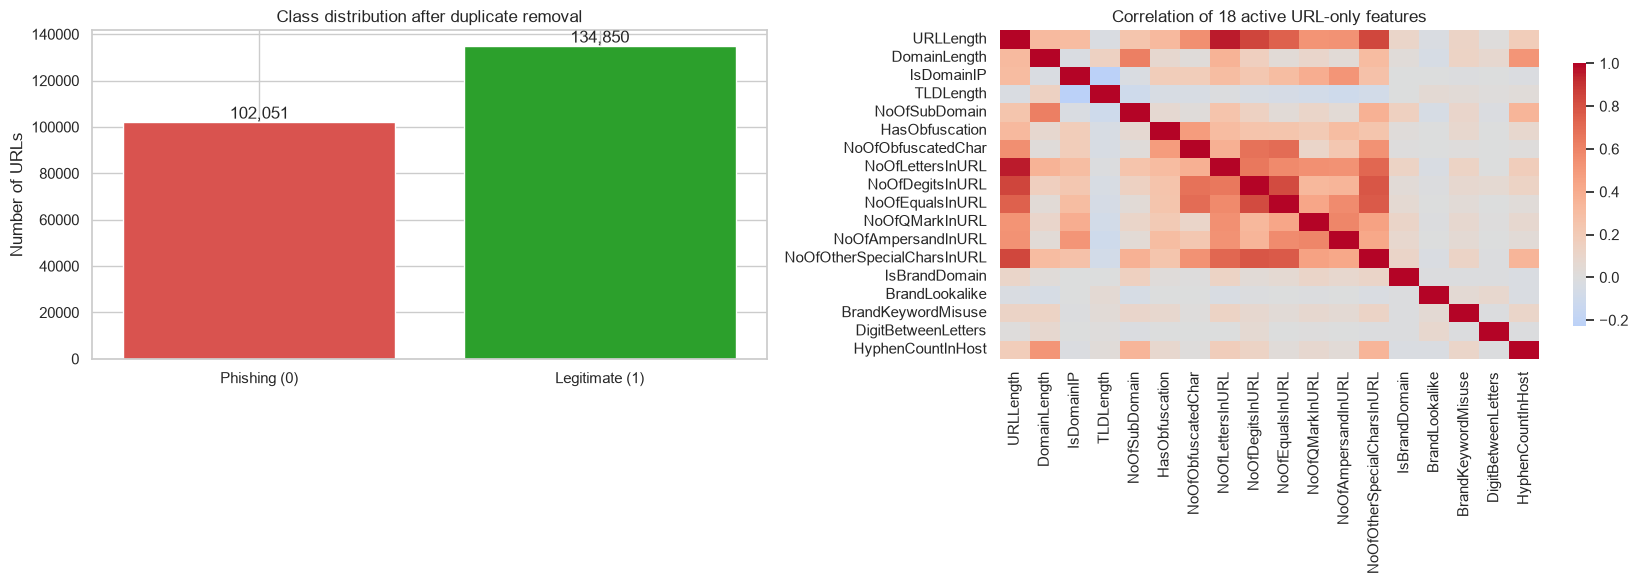

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))

class_counts = y.value_counts().sort_index()
axes[0].bar(["Phishing (0)", "Legitimate (1)"], class_counts.values, color=["#d9534f", "#2ca02c"])
axes[0].set_title("Class distribution after duplicate removal")
axes[0].set_ylabel("Number of URLs")
for index, value in enumerate(class_counts.values):
    axes[0].text(index, value, f"{value:,}", ha="center", va="bottom")

sns.heatmap(X.corr(numeric_only=True), cmap="coolwarm", center=0, ax=axes[1], cbar_kws={"shrink": 0.8})
axes[1].set_title(f"Correlation of {len(FEATURE_NAMES)} active URL-only features")
plt.tight_layout()
plt.show()


### 4.1) ความสัมพันธ์ของทั้ง 18 features

ส่วนนี้ใช้ `all_url_features` (ครบ 18 ตัว) ไม่ใช่ `X` (ชุดที่ใช้เทรนจริง) และไม่รวม Typosquat features ที่เป็น flag 0/1 เพื่อดูว่า feature ไหนซ้ำข้อมูลกัน  
Scatter plot ใช้ตัวอย่างแบบ Stratified เท่านั้น (ไม่พล็อตทั้ง Dataset) เพื่อไม่ให้ช้าหรือกิน RAM

**Correlation heatmap** — ดูภาพรวมทุกคู่ (คำนวณเร็ว ใช้ข้อมูลเต็ม)

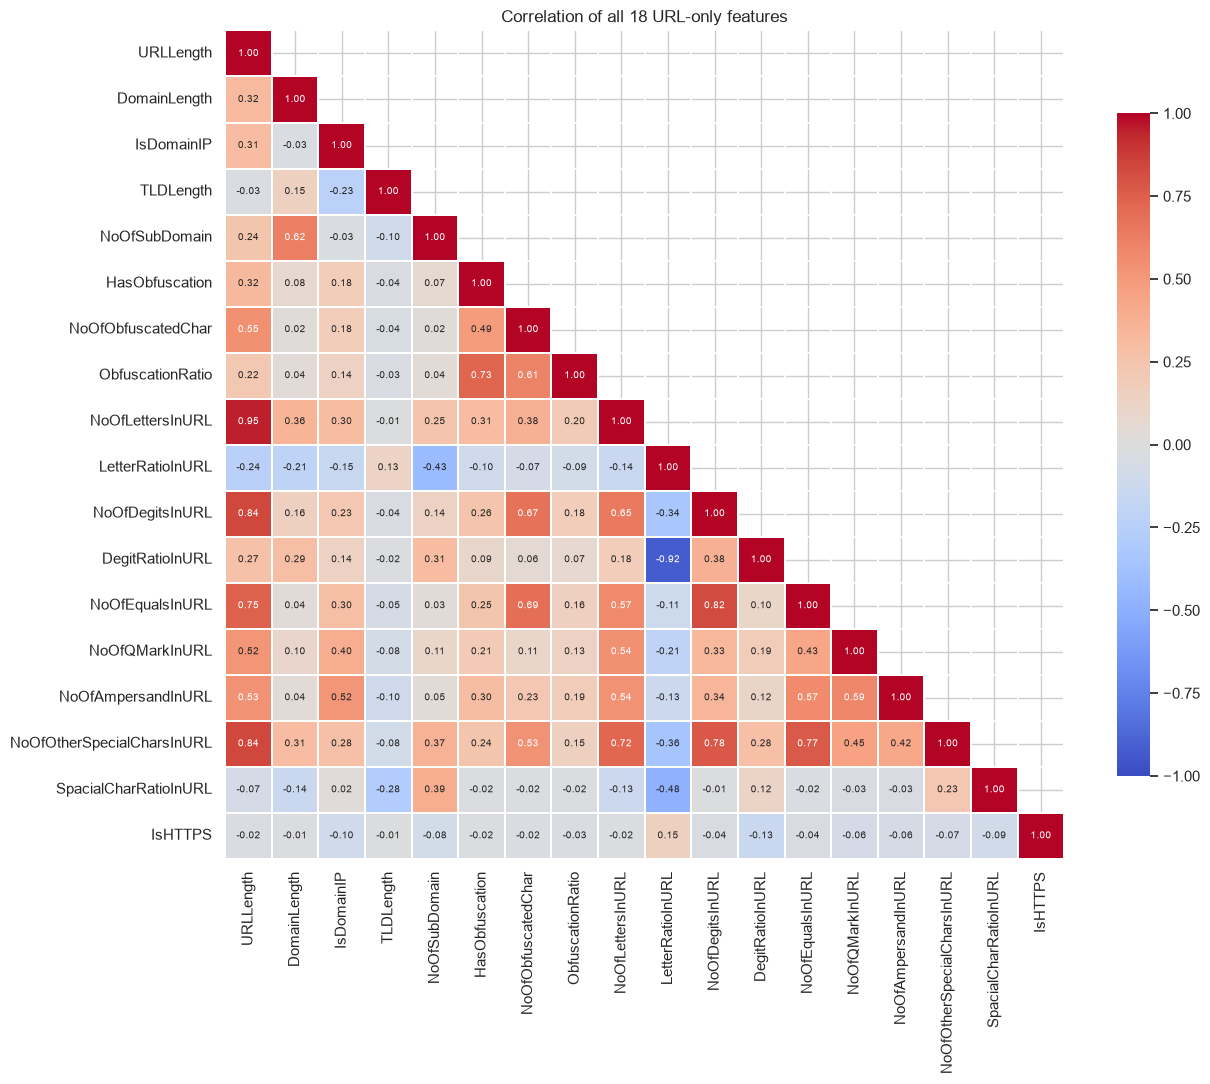

In [13]:
corr = all_url_features[BASE_URL_FEATURE_NAMES].corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(13, 11))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)  # โชว์เฉพาะสามเหลี่ยมล่าง
sns.heatmap(
    corr,
    mask=mask,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7},
    linewidths=0.3,
    cbar_kws={"shrink": 0.8},
    ax=ax,
)
ax.set_title("Correlation of all 18 URL-only features")
plt.tight_layout()
plt.show()

**Scatter plot 12 คู่ที่ |correlation| สูงสุด** — สีตาม Class ปรับขนาดตัวอย่างได้ที่ `PLOT_SAMPLE`

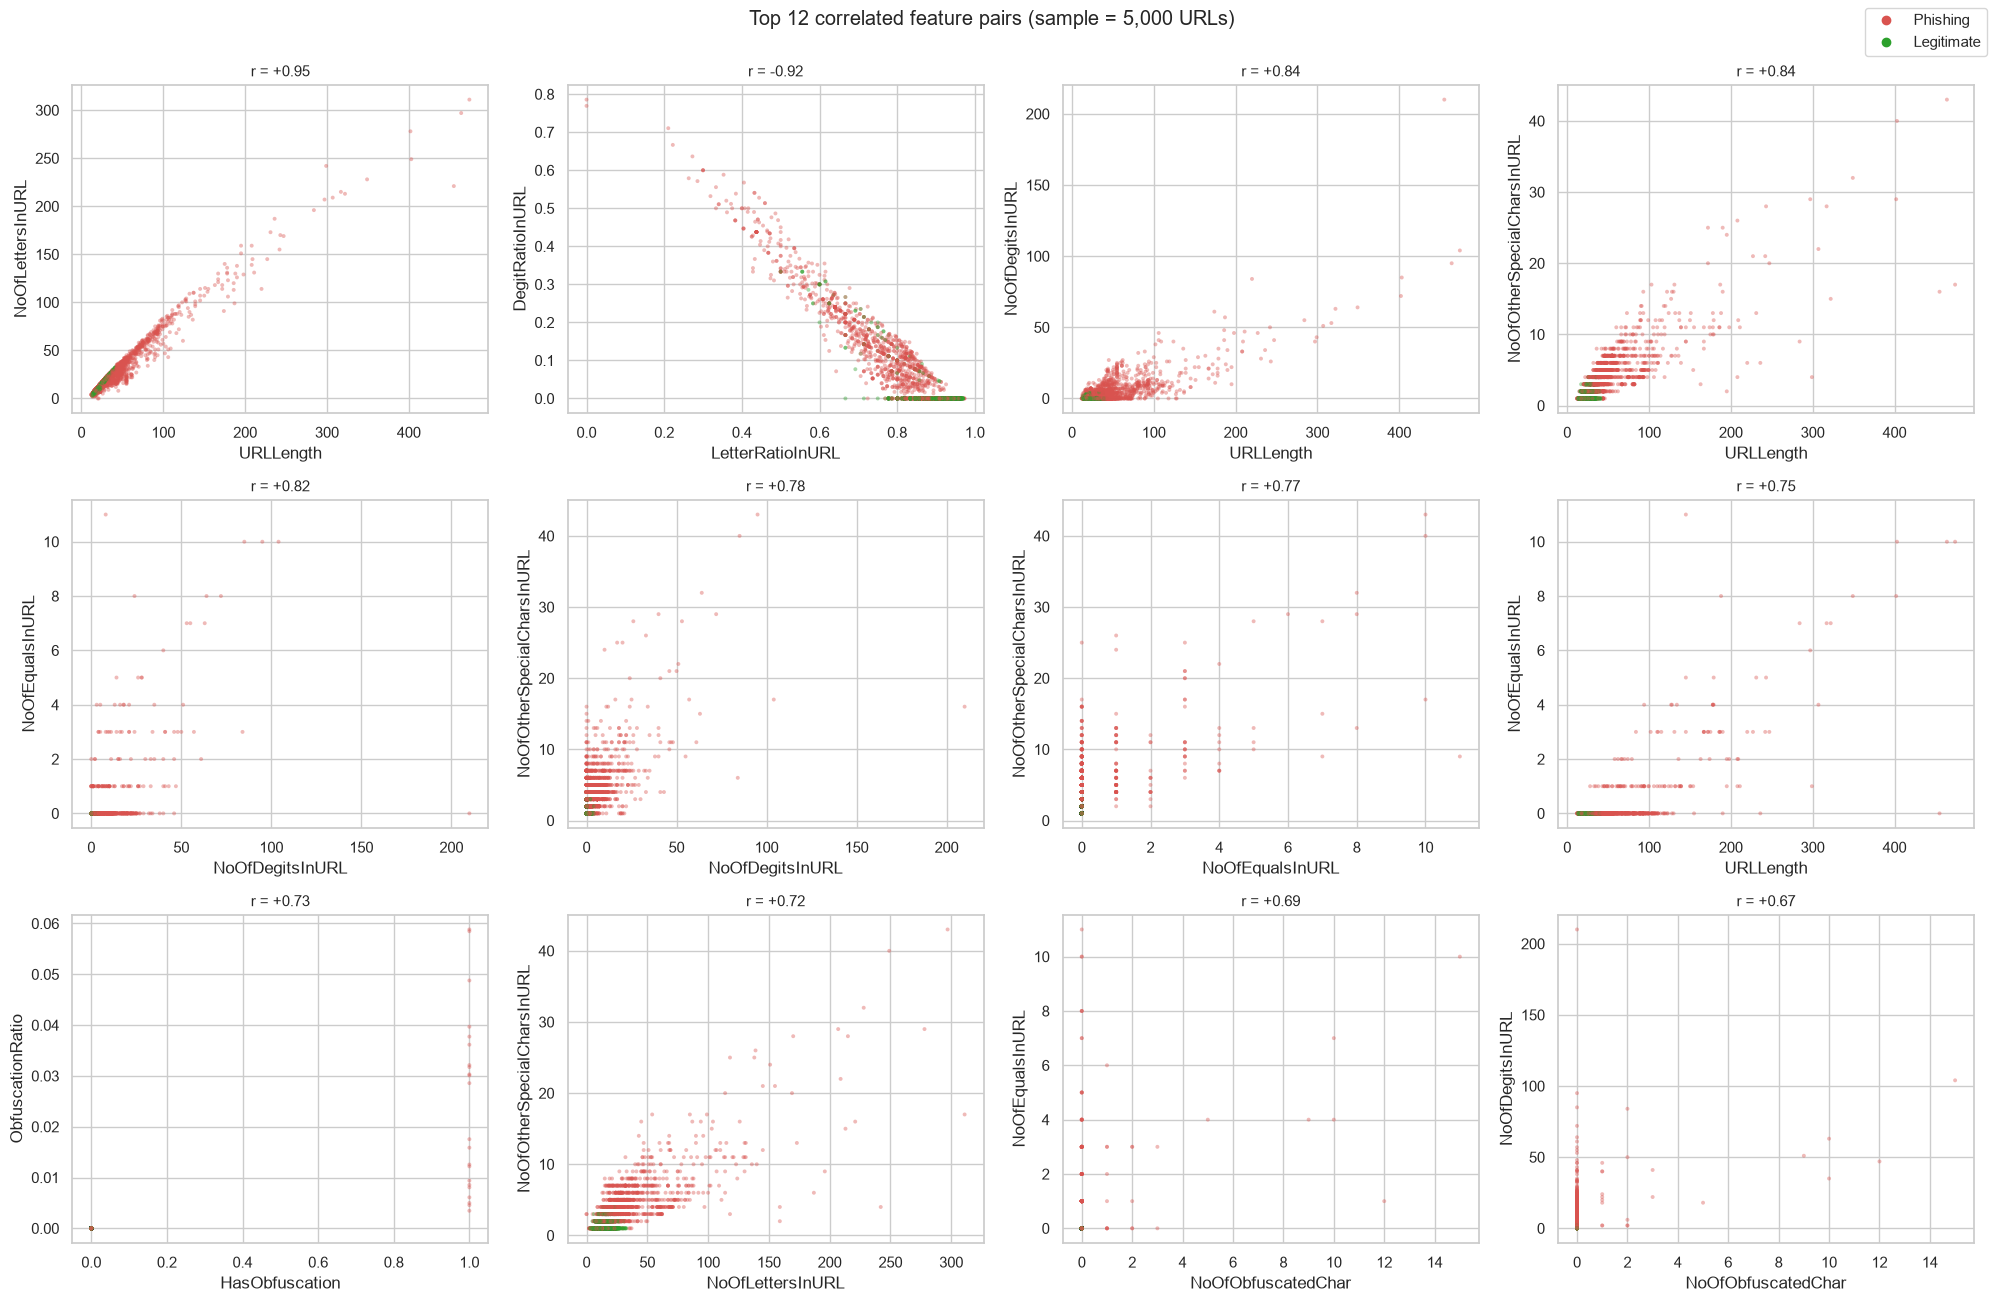

In [14]:
PLOT_SAMPLE = 5_000  # ปรับได้ 2,000–10,000

# สุ่มแบบ stratified เพื่อให้สัดส่วน Phishing/Legitimate เท่าเดิม
plot_df = all_url_features[BASE_URL_FEATURE_NAMES].copy()
plot_df["Class"] = np.where(y.to_numpy() == 0, "Phishing", "Legitimate")
plot_df, _ = train_test_split(
    plot_df,
    train_size=PLOT_SAMPLE,
    stratify=plot_df["Class"],
    random_state=RANDOM_STATE,
)

# หา 12 คู่ที่ |correlation| สูงสุด (นับแต่ละคู่ครั้งเดียว)
upper = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = corr.where(upper).stack().reset_index()
pairs.columns = ["feat_a", "feat_b", "corr"]
top_pairs = pairs.reindex(pairs["corr"].abs().sort_values(ascending=False).index).head(12)

palette = {"Phishing": "#d9534f", "Legitimate": "#2ca02c"}
fig, axes = plt.subplots(3, 4, figsize=(20, 13))

for ax, row in zip(axes.ravel(), top_pairs.itertuples()):
    sns.scatterplot(
        data=plot_df,
        x=row.feat_a,
        y=row.feat_b,
        hue="Class",
        palette=palette,
        s=8,
        alpha=0.4,
        linewidth=0,
        rasterized=True,
        legend=False,
        ax=ax,
    )
    ax.set_title(f"r = {row.corr:+.2f}", fontsize=11)

fig.legend(
    handles=[plt.Line2D([], [], marker="o", ls="", color=c, label=k) for k, c in palette.items()],
    loc="upper right",
)
fig.suptitle(f"Top 12 correlated feature pairs (sample = {PLOT_SAMPLE:,} URLs)", y=1.0)
plt.tight_layout()
plt.show()

**Pairplot 18×18 (ไม่บังคับ)** — ใช้เวลาราว 30 วินาทีที่ 2,000 จุด อย่าตั้ง `PAIRPLOT_SAMPLE` เกิน ~5,000

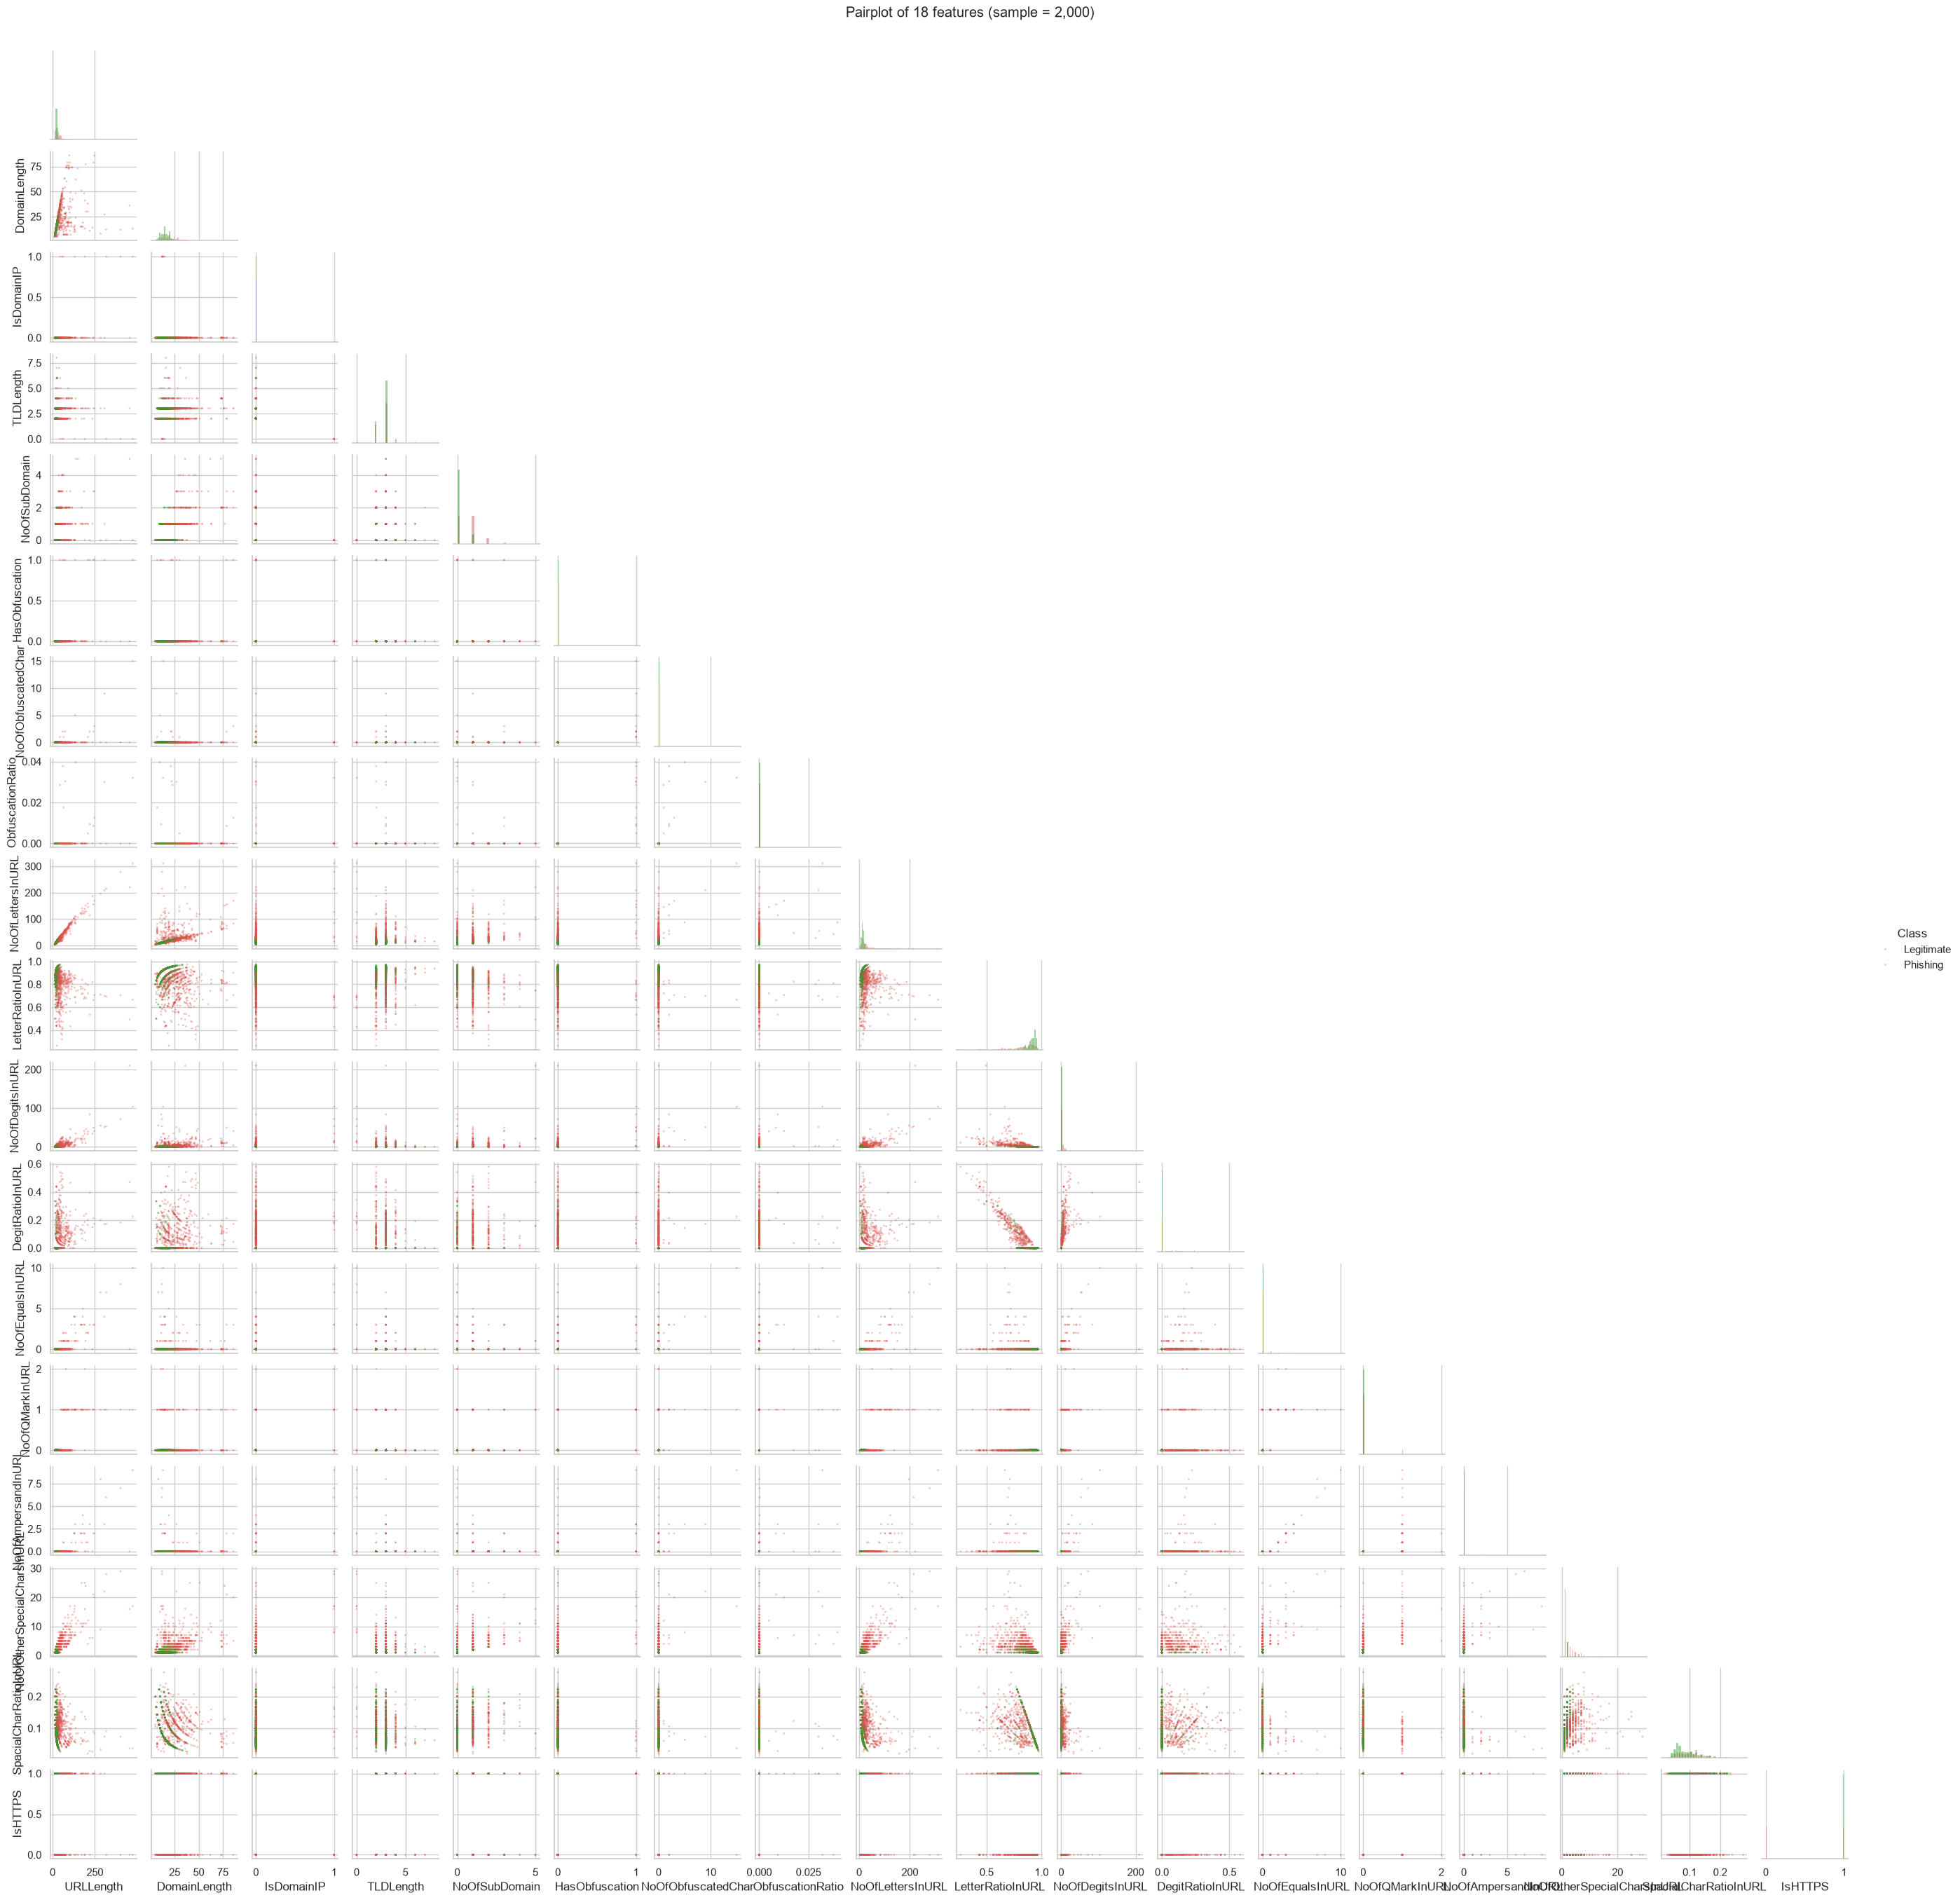

In [15]:
PAIRPLOT_SAMPLE = 2_000  # อย่าตั้งเกิน ~5,000 ไม่งั้นช้าและกิน RAM

labels_text = np.where(y.to_numpy() == 0, "Phishing", "Legitimate")
pp_df, _ = train_test_split(
    all_url_features[BASE_URL_FEATURE_NAMES].assign(Class=labels_text),
    train_size=PAIRPLOT_SAMPLE,
    stratify=labels_text,
    random_state=RANDOM_STATE,
)

g = sns.pairplot(
    pp_df,
    hue="Class",
    palette={"Phishing": "#d9534f", "Legitimate": "#2ca02c"},
    corner=True,          # วาดแค่ครึ่งล่าง ลดจำนวนกราฟจาก 324 เหลือ 171
    diag_kind="hist",     # ใช้ hist แทน kde เพราะ feature ที่เป็น 0/1 ทำ kde พังได้
    height=1.5,
    plot_kws=dict(s=4, alpha=0.35, linewidth=0, rasterized=True),
)
g.figure.suptitle(f"Pairplot of 18 features (sample = {PAIRPLOT_SAMPLE:,})", y=1.01)
plt.show()

## 5) แบ่งข้อมูลแบบ Stratified 56/14/30

ขั้นแรกแยก Test 30% ออกก่อน จากนั้นแบ่ง 70% ที่เหลือเป็น Train 80% และ Validation 20% จึงเท่ากับ 56% และ 14% ของข้อมูลทั้งหมด


In [16]:
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y,
)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval,
    y_trainval,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_trainval,
)

split_summary = pd.DataFrame(
    {
        "Rows": [len(X_train), len(X_val), len(X_test)],
        "Percent": [len(X_train) / len(X), len(X_val) / len(X), len(X_test) / len(X)],
        "Phishing (0)": [(labels == 0).sum() for labels in (y_train, y_val, y_test)],
        "Legitimate (1)": [(labels == 1).sum() for labels in (y_train, y_val, y_test)],
    },
    index=["Train", "Validation", "Test"],
)
split_summary["Percent"] = (split_summary["Percent"] * 100).round(2).astype(str) + "%"
display(split_summary)


,Rows,Percent,Phishing (0),Legitimate (1)
Train,132664,56.0%,57148,75516
Validation,33166,14.0%,14287,18879
Test,71071,30.0%,30616,40455


## 6) Metric และโมเดล

ใน Dataset นี้ Phishing มี label เป็น 0 ดังนั้น Precision, Recall และ F1 ด้านล่างกำหนด `pos_label=0` อย่างชัดเจน

StandardScaler ใช้กับ KNN และ Linear SVM เพราะโมเดลทั้งสองไวต่อสเกลของ Feature ส่วน Tree-based models และ GaussianNB ไม่ต้องใช้ Scaling


In [17]:
def phishing_metrics(y_true, y_pred):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision_Phishing": precision_score(y_true, y_pred, pos_label=0, zero_division=0),
        "Recall_Phishing": recall_score(y_true, y_pred, pos_label=0, zero_division=0),
        "F1_Phishing": f1_score(y_true, y_pred, pos_label=0, zero_division=0),
    }


def build_model(model_name, params):
    if model_name == "KNN":
        return Pipeline(
            [
                ("scaler", StandardScaler()),
                (
                    "model",
                    KNeighborsClassifier(
                        n_neighbors=params["n_neighbors"],
                        weights="uniform",
                        n_jobs=-1,
                    ),
                ),
            ]
        )

    if model_name == "Decision Tree":
        return DecisionTreeClassifier(random_state=RANDOM_STATE, **params)

    if model_name == "Gaussian Naive Bayes":
        return GaussianNB(**params)

    if model_name == "Random Forest":
        return RandomForestClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            **params,
        )

    if model_name == "XGBoost":
        return XGBClassifier(
            random_state=RANDOM_STATE,
            n_jobs=-1,
            tree_method="hist",
            eval_metric="logloss",
            colsample_bytree=0.9,
            **params,
        )

    if model_name == "Linear SVM":
        return Pipeline(
            [
                ("scaler", StandardScaler()),
                (
                    "model",
                    LinearSVC(
                        random_state=RANDOM_STATE,
                        dual=False,
                        max_iter=10_000,
                        **params,
                    ),
                ),
            ]
        )

    raise ValueError(f"ไม่รู้จักโมเดล: {model_name}")


MODEL_GRIDS = {
    "KNN": {"n_neighbors": [3, 7, 11]},
    "Decision Tree": {"max_depth": [10, None], "min_samples_leaf": [1, 5]},
    "Gaussian Naive Bayes": {"var_smoothing": [1e-9, 1e-8, 1e-7]},
    "Random Forest": {
        "n_estimators": [200],
        "max_depth": [20, None],
        "min_samples_leaf": [1, 3],
        "class_weight": [None],
    },
    "XGBoost": {
        "n_estimators": [200],
        "max_depth": [4, 6],
        "learning_rate": [0.10],
        "subsample": [0.90],
    },
    # ค่า C เล็กลงเพื่อเพิ่ม Regularization; ไม่ใช้ class_weight เพราะ Class ไม่ได้ต่างกันรุนแรง
    "Linear SVM": {"C": [0.001, 0.01, 0.1, 1.0], "class_weight": [None]},
}

print("จำนวนชุด Hyperparameter")
for name, grid in MODEL_GRIDS.items():
    print(f"- {name}: {len(list(ParameterGrid(grid)))} ชุด")


จำนวนชุด Hyperparameter
- KNN: 3 ชุด
- Decision Tree: 4 ชุด
- Gaussian Naive Bayes: 3 ชุด
- Random Forest: 4 ชุด
- XGBoost: 2 ชุด
- Linear SVM: 4 ชุด


## 7) Hyperparameter tuning แบบจำกัดเวลา

เพื่อให้อยู่ในกรอบประมาณ 30–60 นาที ขั้นตอนค้นหาค่าใช้ตัวอย่างแบบ Stratified จาก Train/Validation  
หลังเลือกค่าที่ดีที่สุดของแต่ละโมเดลแล้ว Cell ถัดไปจะ Train ใหม่ด้วย **Train 56% เต็มชุด** และตรวจบน Validation 14% เต็มชุด


In [18]:
def stratified_limit(X_part, y_part, max_rows, seed_offset=0):
    if max_rows is None or len(X_part) <= max_rows:
        return X_part, y_part
    X_sample, _, y_sample, _ = train_test_split(
        X_part,
        y_part,
        train_size=max_rows,
        random_state=RANDOM_STATE + seed_offset,
        stratify=y_part,
    )
    return X_sample, y_sample


X_tune_train, y_tune_train = stratified_limit(
    X_train, y_train, TUNE_TRAIN_LIMIT, seed_offset=1
)
X_tune_val, y_tune_val = stratified_limit(
    X_val, y_val, TUNE_VALIDATION_LIMIT, seed_offset=2
)

print(f"Tuning train: {len(X_tune_train):,} แถว")
print(f"Tuning validation: {len(X_tune_val):,} แถว")

tuning_rows = []
best_params_by_model = {}

for model_name, grid in MODEL_GRIDS.items():
    print(f"\nกำลังทดลอง {model_name}")
    model_rows = []

    for params in ParameterGrid(grid):
        start = time.perf_counter()
        candidate = build_model(model_name, params)
        candidate.fit(X_tune_train, y_tune_train)
        predictions = candidate.predict(X_tune_val)
        elapsed = time.perf_counter() - start

        row = {
            "Model": model_name,
            "Parameters": params.copy(),
            "Seconds": elapsed,
            **phishing_metrics(y_tune_val, predictions),
        }
        model_rows.append(row)
        tuning_rows.append(row)
        print(
            f"  {params} -> F1={row['F1_Phishing']:.4f}, "
            f"Recall={row['Recall_Phishing']:.4f}, {elapsed:.1f}s"
        )

    model_rows.sort(
        key=lambda item: (item["F1_Phishing"], item["Recall_Phishing"]),
        reverse=True,
    )
    best_params_by_model[model_name] = model_rows[0]["Parameters"]

tuning_results = pd.DataFrame(tuning_rows).sort_values(
    ["Model", "F1_Phishing", "Recall_Phishing"],
    ascending=[True, False, False],
)
display(tuning_results.reset_index(drop=True))

print("\nค่าที่เลือกของแต่ละโมเดล")
for name, params in best_params_by_model.items():
    print(f"- {name}: {params}")


Tuning train: 50,000 แถว
Tuning validation: 15,000 แถว

กำลังทดลอง KNN
  {'n_neighbors': 3} -> F1=0.9472, Recall=0.9581, 0.9s
  {'n_neighbors': 7} -> F1=0.9618, Recall=0.9496, 0.8s
  {'n_neighbors': 11} -> F1=0.9583, Recall=0.9451, 0.8s

กำลังทดลอง Decision Tree
  {'max_depth': 10, 'min_samples_leaf': 1} -> F1=0.8704, Recall=0.7967, 0.1s
  {'max_depth': 10, 'min_samples_leaf': 5} -> F1=0.8700, Recall=0.7973, 0.1s
  {'max_depth': None, 'min_samples_leaf': 1} -> F1=0.9750, Recall=0.9644, 0.1s
  {'max_depth': None, 'min_samples_leaf': 5} -> F1=0.9718, Recall=0.9608, 0.1s

กำลังทดลอง Gaussian Naive Bayes
  {'var_smoothing': 1e-09} -> F1=0.6190, Recall=0.4578, 0.0s
  {'var_smoothing': 1e-08} -> F1=0.6329, Recall=0.4729, 0.0s
  {'var_smoothing': 1e-07} -> F1=0.6503, Recall=0.4927, 0.0s

กำลังทดลอง Random Forest
  {'class_weight': None, 'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 200} -> F1=0.9743, Recall=0.9647, 0.9s
  {'class_weight': None, 'max_depth': 20, 'min_samples_leaf': 3

,Model,Parameters,Seconds,Accuracy,Precision_Phishing,Recall_Phishing,F1_Phishing
0,Decision Tree,"{'max_depth': None, 'min_samples_leaf': 1}",0.073103,0.978733,0.985920,0.964407,0.975045
1,Decision Tree,"{'max_depth': None, 'min_samples_leaf': 5}",0.069556,0.975933,0.982903,0.960848,0.971751
2,Decision Tree,"{'max_depth': 10, 'min_samples_leaf': 1}",0.075520,0.897800,0.959195,0.796657,0.870403
3,Decision Tree,"{'max_depth': 10, 'min_samples_leaf': 5}",0.057139,0.897400,0.957443,0.797276,0.870050
4,Gaussian Naive Bayes,{'var_smoothing': 1e-07},0.015616,0.771667,0.955869,0.492727,0.650260
5,Gaussian Naive Bayes,{'var_smoothing': 1e-08},0.015910,0.763667,0.956495,0.472919,0.632909
6,Gaussian Naive Bayes,{'var_smoothing': 1e-09},0.017107,0.757200,0.955426,0.457753,0.618958
7,KNN,{'n_neighbors': 7},0.790075,0.967533,0.974432,0.949551,0.961831
8,KNN,{'n_neighbors': 11},0.805381,0.964533,0.971833,0.945063,0.958261
9,KNN,{'n_neighbors': 3},0.920365,0.954000,0.936611,0.958063,0.947215



ค่าที่เลือกของแต่ละโมเดล
- KNN: {'n_neighbors': 7}
- Decision Tree: {'max_depth': None, 'min_samples_leaf': 1}
- Gaussian Naive Bayes: {'var_smoothing': 1e-07}
- Random Forest: {'class_weight': None, 'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 200}
- XGBoost: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 200, 'subsample': 0.9}
- Linear SVM: {'C': 1.0, 'class_weight': None}


## 8) Train ด้วย Training Set เต็มและเลือกผู้ชนะจาก Validation Set

โมเดลผู้ชนะถูกเลือกก่อนแตะ Test Set โดยเรียงจาก F1 ของ Phishing แล้วใช้ Recall ของ Phishing เป็นตัวตัดสินกรณีคะแนนใกล้กัน


In [19]:
fitted_models = {}
validation_predictions = {}
validation_rows = []

for model_name, params in best_params_by_model.items():
    print(f"กำลัง Train {model_name} ด้วย Training Set เต็ม...")
    start = time.perf_counter()
    model = build_model(model_name, params)
    model.fit(X_train, y_train)
    predictions = model.predict(X_val)
    elapsed = time.perf_counter() - start

    fitted_models[model_name] = model
    validation_predictions[model_name] = predictions
    validation_rows.append(
        {
            "Model": model_name,
            "Seconds": elapsed,
            **phishing_metrics(y_val, predictions),
        }
    )

validation_results = pd.DataFrame(validation_rows).sort_values(
    ["F1_Phishing", "Recall_Phishing"], ascending=False
).reset_index(drop=True)

selected_model_name = validation_results.loc[0, "Model"]
selected_model = fitted_models[selected_model_name]

display(validation_results.style.format({
    "Seconds": "{:.1f}",
    "Accuracy": "{:.4f}",
    "Precision_Phishing": "{:.4f}",
    "Recall_Phishing": "{:.4f}",
    "F1_Phishing": "{:.4f}",
}))
print(f"\nโมเดลที่เลือกจาก Validation Set: {selected_model_name}")

# ตรวจ Generalization gap แบบเบา ๆ ด้วยตัวอย่างจาก Training Set
X_gap_train, y_gap_train = stratified_limit(
    X_train, y_train, max_rows=15_000, seed_offset=3
)
train_gap_predictions = selected_model.predict(X_gap_train)
train_gap_metrics = phishing_metrics(y_gap_train, train_gap_predictions)
selected_validation_metrics = validation_results.loc[
    validation_results["Model"] == selected_model_name
].iloc[0]
f1_gap = train_gap_metrics["F1_Phishing"] - selected_validation_metrics["F1_Phishing"]

print(f"Training-sample F1: {train_gap_metrics['F1_Phishing']:.4f}")
print(f"Validation F1:      {selected_validation_metrics['F1_Phishing']:.4f}")
print(f"Generalization gap: {f1_gap:.4f}")
print("หมายเหตุ: gap เล็กไม่ได้ลบปัญหา Dataset Bias เพราะ Train/Validation มาจากแหล่งเดียวกัน")


กำลัง Train KNN ด้วย Training Set เต็ม...
กำลัง Train Decision Tree ด้วย Training Set เต็ม...
กำลัง Train Gaussian Naive Bayes ด้วย Training Set เต็ม...
กำลัง Train Random Forest ด้วย Training Set เต็ม...
กำลัง Train XGBoost ด้วย Training Set เต็ม...
กำลัง Train Linear SVM ด้วย Training Set เต็ม...


,Model,Seconds,Accuracy,Precision_Phishing,Recall_Phishing,F1_Phishing
0,XGBoost,0.6,0.9800,0.9875,0.9658,0.9765
1,Decision Tree,0.2,0.9800,0.9880,0.9653,0.9765
2,Random Forest,4.2,0.9785,0.9869,0.9628,0.9747
3,KNN,4.8,0.9753,0.9826,0.9597,0.9710
4,Linear SVM,23.4,0.9674,0.9833,0.9403,0.9613
5,Gaussian Naive Bayes,0.0,0.7718,0.9586,0.4914,0.6497



โมเดลที่เลือกจาก Validation Set: XGBoost
Training-sample F1: 0.9796
Validation F1:      0.9765
Generalization gap: 0.0031
หมายเหตุ: gap เล็กไม่ได้ลบปัญหา Dataset Bias เพราะ Train/Validation มาจากแหล่งเดียวกัน


## 9) ประเมิน Test Set ครั้งสุดท้าย

ผู้ชนะถูกกำหนดจาก Validation Set แล้ว ตาราง Test ใช้รายงานประสิทธิภาพสุดท้าย ไม่ควรย้อนกลับไปปรับ Hyperparameter จากผลตารางนี้


In [20]:
test_rows = []
test_predictions = {}

for model_name, model in fitted_models.items():
    print(f"กำลังทดสอบ {model_name}...")
    start = time.perf_counter()
    predictions = model.predict(X_test)
    elapsed = time.perf_counter() - start
    test_predictions[model_name] = predictions
    test_rows.append(
        {
            "Model": model_name,
            "Selected_by_Validation": model_name == selected_model_name,
            "Predict_Seconds": elapsed,
            **phishing_metrics(y_test, predictions),
        }
    )

test_results = pd.DataFrame(test_rows).sort_values(
    ["F1_Phishing", "Recall_Phishing"], ascending=False
).reset_index(drop=True)

display(test_results.style.format({
    "Predict_Seconds": "{:.1f}",
    "Accuracy": "{:.4f}",
    "Precision_Phishing": "{:.4f}",
    "Recall_Phishing": "{:.4f}",
    "F1_Phishing": "{:.4f}",
}))
print(f"โมเดลที่กำหนดเป็นผู้ชนะก่อนดู Test: {selected_model_name}")


กำลังทดสอบ KNN...
กำลังทดสอบ Decision Tree...
กำลังทดสอบ Gaussian Naive Bayes...
กำลังทดสอบ Random Forest...
กำลังทดสอบ XGBoost...
กำลังทดสอบ Linear SVM...


,Model,Selected_by_Validation,Predict_Seconds,Accuracy,Precision_Phishing,Recall_Phishing,F1_Phishing
0,Decision Tree,False,0.0,0.9796,0.9873,0.9652,0.9761
1,XGBoost,True,0.0,0.9795,0.9873,0.9647,0.9759
2,Random Forest,False,0.2,0.9782,0.9866,0.9624,0.9743
3,KNN,False,9.6,0.9745,0.9824,0.9580,0.9701
4,Linear SVM,False,0.0,0.9689,0.9849,0.9423,0.9631
5,Gaussian Naive Bayes,False,0.0,0.7750,0.9591,0.4991,0.6565


โมเดลที่กำหนดเป็นผู้ชนะก่อนดู Test: XGBoost


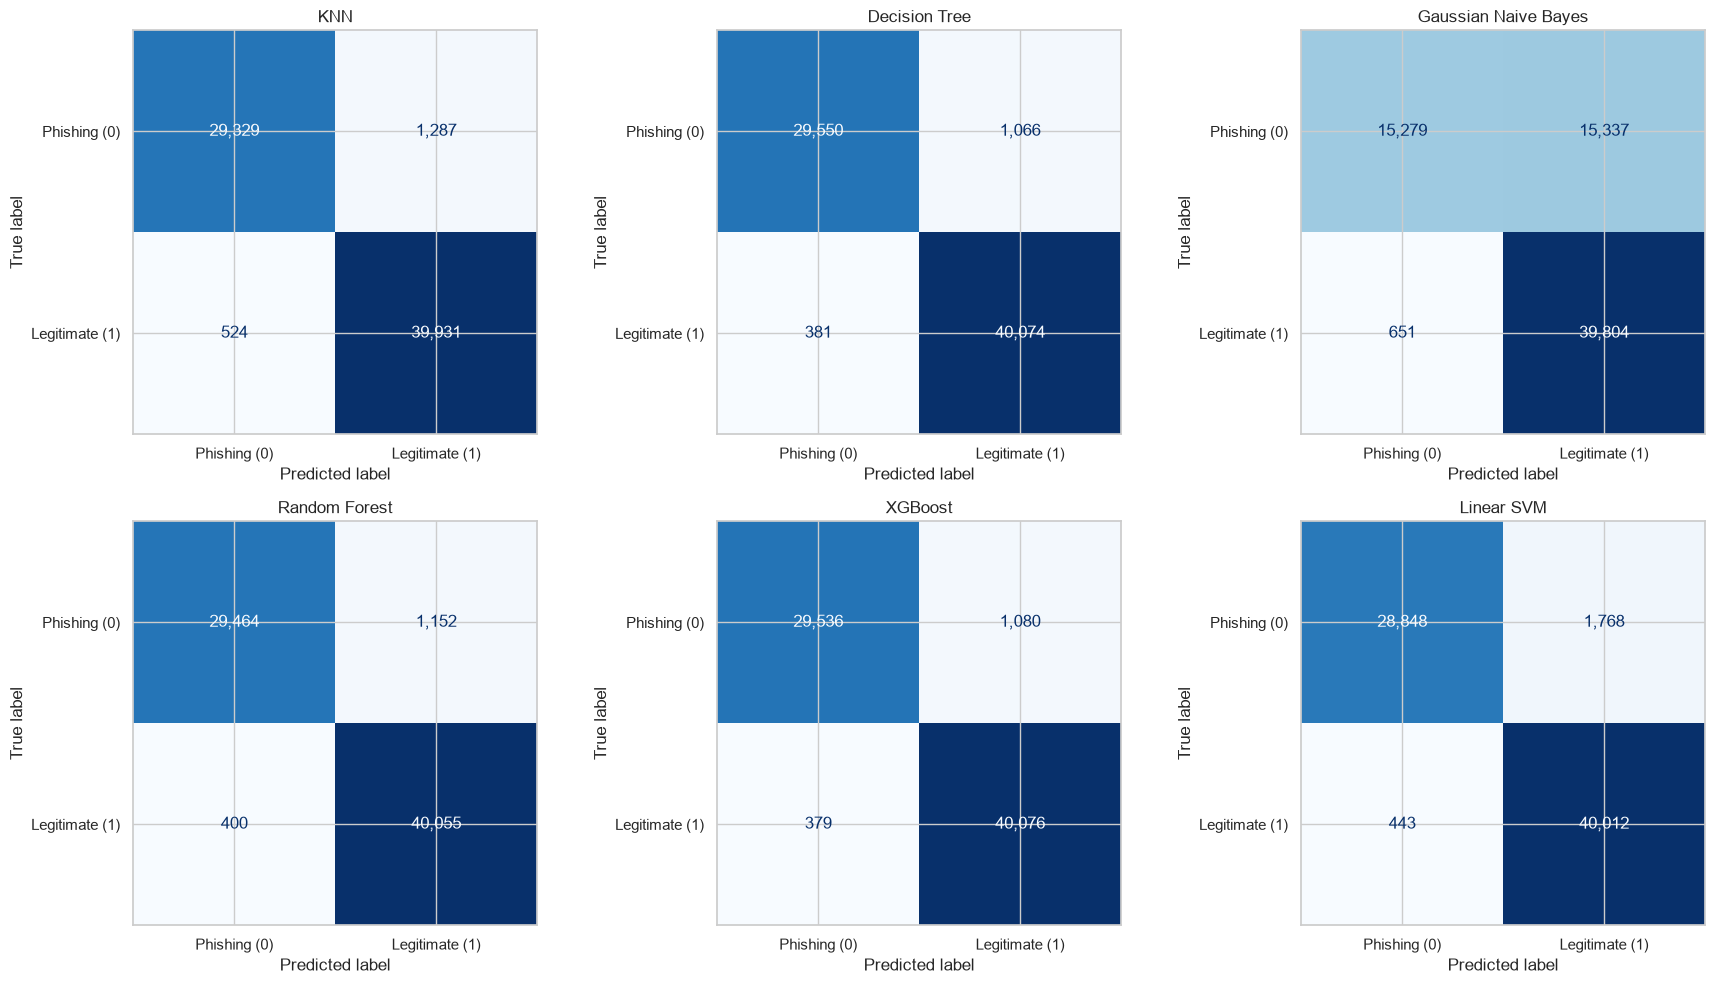

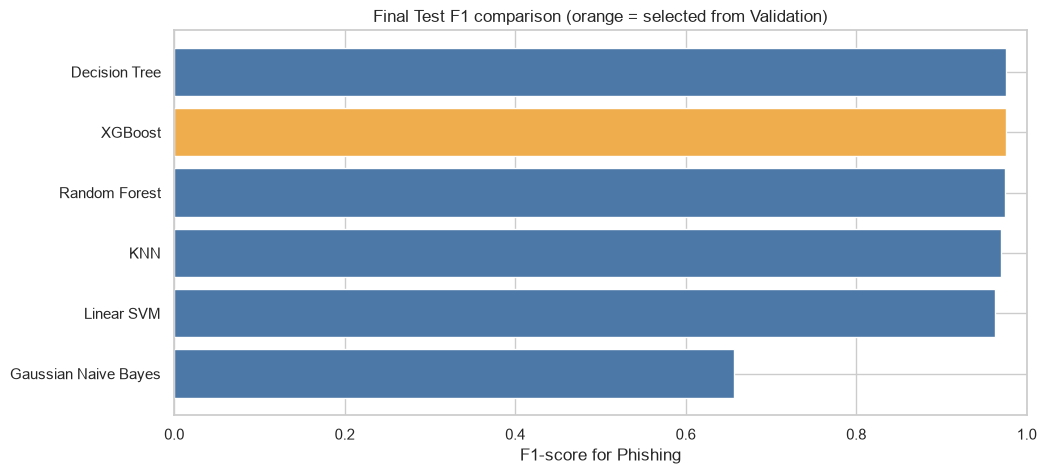

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for ax, model_name in zip(axes, fitted_models):
    matrix = confusion_matrix(y_test, test_predictions[model_name], labels=[0, 1])
    ConfusionMatrixDisplay(
        confusion_matrix=matrix,
        display_labels=["Phishing (0)", "Legitimate (1)"],
    ).plot(ax=ax, colorbar=False, cmap="Blues", values_format=",d")
    ax.set_title(model_name)

plt.tight_layout()
plt.show()

plt.figure(figsize=(11, 5))
ordered = test_results.sort_values("F1_Phishing", ascending=True)
colors = ["#f0ad4e" if name == selected_model_name else "#4c78a8" for name in ordered["Model"]]
plt.barh(ordered["Model"], ordered["F1_Phishing"], color=colors)
plt.xlim(0, 1)
plt.xlabel("F1-score for Phishing")
plt.title("Final Test F1 comparison (orange = selected from Validation)")
plt.show()


### 9.1) แยกผลบน Test: ข้อมูลจริง vs Typosquat สังเคราะห์

ตัวเลขรวมด้านบนปนกันสองแหล่ง ตารางนี้แยกให้เห็นว่าการเพิ่ม Typosquat ไม่ได้ทำให้ผลบนข้อมูลจริงเสีย

In [22]:
# แยกผลบน Test Set ระหว่างข้อมูลจริง กับ Typosquat สังเคราะห์
test_source = df.loc[X_test.index, "source"].to_numpy()
subgroup_rows = []
for subset_name, mask in [("ข้อมูลจริง", test_source == "real"), ("typosquat สังเคราะห์", test_source != "real")]:
    if mask.sum() == 0:
        continue
    predictions = selected_model.predict(X_test[mask])
    subgroup_rows.append(
        {"Subset": subset_name, "Rows": int(mask.sum()), **phishing_metrics(y_test[mask], predictions)}
    )

display(pd.DataFrame(subgroup_rows).round(4))
print("หมายเหตุ: ชุดสังเคราะห์มีแต่ Phishing ให้ดู Recall_Phishing เป็นหลัก ส่วน Precision/F1 ของชุดนี้ไม่มีความหมาย")

,Subset,Rows,Accuracy,Precision_Phishing,Recall_Phishing,F1_Phishing
0,ข้อมูลจริง,70597,0.9794,0.9871,0.9642,0.9755
1,typosquat สังเคราะห์,474,0.9958,1.0000,0.9958,0.9979


หมายเหตุ: ชุดสังเคราะห์มีแต่ Phishing ให้ดู Recall_Phishing เป็นหลัก ส่วน Precision/F1 ของชุดนี้ไม่มีความหมาย


## 10) สร้างช่วง Suspicious จาก Validation Set

1. แปลงผลของโมเดลเป็นคะแนนที่ **ค่ายิ่งสูงยิ่งเสี่ยงเป็น Phishing**
2. หา Binary threshold ที่ทำให้ F1 ของ Phishing บน Validation สูงสุด
3. ใช้ URL ที่มีคะแนนใกล้เส้นแบ่งที่สุดประมาณ 10% เป็น Suspicious

ค่า 10% ปรับได้ด้วย `TARGET_SUSPICIOUS_RATE` ที่ Cell ตั้งค่า โดยไม่แสดงคะแนนนี้แก่ผู้ใช้


In [23]:
def phishing_risk_score(model, X_input):
    classes = np.asarray(model.classes_)

    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X_input)
        phishing_column = int(np.where(classes == 0)[0][0])
        return probabilities[:, phishing_column]

    if hasattr(model, "decision_function"):
        decision = np.asarray(model.decision_function(X_input))
        if decision.ndim != 1 or len(classes) != 2:
            raise ValueError("รองรับ decision_function แบบ Binary เท่านั้น")
        # Binary decision_function: ค่าบวกชี้ไป classes_[1]
        return -decision if classes[1] == 1 else decision

    raise TypeError("โมเดลไม่มี predict_proba หรือ decision_function")


def find_balanced_suspicious_band(model, X_validation, y_validation, suspicious_rate=0.10):
    scores = phishing_risk_score(model, X_validation)
    y_phishing = (np.asarray(y_validation) == 0).astype(int)

    precision, recall, thresholds = precision_recall_curve(y_phishing, scores)
    if len(thresholds) == 0:
        raise ValueError("ไม่สามารถหา Threshold จาก Validation Set ได้")

    f1_values = 2 * precision[:-1] * recall[:-1] / np.maximum(
        precision[:-1] + recall[:-1], 1e-12
    )
    best_index = int(np.nanargmax(f1_values))
    binary_threshold = float(thresholds[best_index])

    distance_from_boundary = np.abs(scores - binary_threshold)
    band_width = float(np.quantile(distance_from_boundary, suspicious_rate))
    lower_threshold = binary_threshold - band_width
    upper_threshold = binary_threshold + band_width

    return {
        "binary_threshold": binary_threshold,
        "lower_threshold": lower_threshold,
        "upper_threshold": upper_threshold,
        "band_width": band_width,
        "target_suspicious_rate": suspicious_rate,
    }


suspicious_config = find_balanced_suspicious_band(
    selected_model,
    X_val,
    y_val,
    suspicious_rate=TARGET_SUSPICIOUS_RATE,
)


def predict_three_levels(model, X_input, config):
    scores = phishing_risk_score(model, X_input)
    return np.where(
        scores >= config["upper_threshold"],
        "Phishing",
        np.where(scores <= config["lower_threshold"], "Legitimate", "Suspicious"),
    )


validation_three_level = predict_three_levels(selected_model, X_val, suspicious_config)
suspicious_rate_observed = np.mean(validation_three_level == "Suspicious")
decided_mask = validation_three_level != "Suspicious"
decided_numeric = np.where(validation_three_level[decided_mask] == "Phishing", 0, 1)
decided_accuracy = accuracy_score(np.asarray(y_val)[decided_mask], decided_numeric)

print(f"โมเดล: {selected_model_name}")
print(f"Validation ที่ถูกจัดเป็น Suspicious: {suspicious_rate_observed:.2%}")
print(f"Accuracy เฉพาะรายการที่ตัดสินชัดเจน: {decided_accuracy:.4f}")

test_three_level = predict_three_levels(selected_model, X_test, suspicious_config)
print("\nจำนวนผลลัพธ์ 3 ระดับบน Test Set")
display(pd.Series(test_three_level).value_counts().to_frame("Count"))


โมเดล: XGBoost
Validation ที่ถูกจัดเป็น Suspicious: 9.81%
Accuracy เฉพาะรายการที่ตัดสินชัดเจน: 0.9892

จำนวนผลลัพธ์ 3 ระดับบน Test Set


,Count
Legitimate,39491
Phishing,24698
Suspicious,6882


## 11) Sanity Check กับ URL นอก Dataset

ชุดนี้ไม่ใช่ Metric ทางการ แต่ช่วยจับอาการคะแนน Test สูงแต่ใช้งานกับ URL ปกติไม่ได้ โดยเฉพาะ URL ที่มี root slash, ไม่มี `www` หรือมี Path


In [24]:
sanity_cases = [
    ("https://www.google.com", "Legitimate"),
    ("https://www.google.com/", "Legitimate"),
    ("https://google.com", "Legitimate"),
    ("https://www.python.org/", "Legitimate"),
    ("https://docs.python.org/3/tutorial/", "Legitimate"),
    ("https://github.com/openai/openai-python", "Legitimate"),
    ("http://paypal-login-check-98421.invalid/account/verify?session=493820", "Phishing"),
    ("https://secure-bank-update-77193.invalid/customer/login?token=ab93xz", "Phishing"),
    # Typosquatting (v1.3): แบรนด์จริงควรเป็น Legitimate ส่วนชื่อเลียนแบบควรเป็น Phishing
    ("https://youtube.com", "Legitimate"),
    ("https://y0utube.com", "Phishing"),
    ("https://g00gle.com", "Phishing"),
    ("https://paypa1.com", "Phishing"),
    ("https://faceb00k.com", "Phishing"),
    ("https://kasikornbamk.com", "Phishing"),
]

sanity_rows = []
for url, expected in sanity_cases:
    feature_frame = pd.DataFrame(
        [extract_url_features(url)],
        columns=FEATURE_NAMES,
    )
    predicted = predict_three_levels(
        selected_model,
        feature_frame,
        suspicious_config,
    )[0]
    sanity_rows.append(
        {
            "URL": url,
            "Normalized": normalize_url(url),
            "Expected": expected,
            "Predicted": predicted,
            "Exact Match": predicted == expected,
        }
    )

sanity_results = pd.DataFrame(sanity_rows)
display(sanity_results)
print("หาก URL Legitimate ที่มี Path ยังผิด แปลว่า Dataset ต้องเพิ่ม Legitimate URL ที่มี Path/Query")
print("Typosquat: ผลเป็น Suspicious ถือว่ายอมรับได้ (ไม่ปล่อยผ่านเป็น Legitimate) แต่ Exact Match จะเป็น False")

,URL,Normalized,Expected,Predicted,Exact Match
0,https://www.google.com,https://google.com,Legitimate,Legitimate,True
1,https://www.google.com/,https://google.com,Legitimate,Legitimate,True
2,https://google.com,https://google.com,Legitimate,Legitimate,True
3,https://www.python.org/,https://python.org,Legitimate,Legitimate,True
4,https://docs.python.org/3/tutorial/,https://docs.python.org/3/tutorial/,Legitimate,Phishing,False
5,https://github.com/openai/openai-python,https://github.com/openai/openai-python,Legitimate,Phishing,False
6,http://paypal-login-check-98421.invalid/accoun...,http://paypal-login-check-98421.invalid/accoun...,Phishing,Phishing,True
7,https://secure-bank-update-77193.invalid/custo...,https://secure-bank-update-77193.invalid/custo...,Phishing,Phishing,True
8,https://youtube.com,https://youtube.com,Legitimate,Legitimate,True
9,https://y0utube.com,https://y0utube.com,Phishing,Phishing,True


หาก URL Legitimate ที่มี Path ยังผิด แปลว่า Dataset ต้องเพิ่ม Legitimate URL ที่มี Path/Query
Typosquat: ผลเป็น Suspicious ถือว่ายอมรับได้ (ไม่ปล่อยผ่านเป็น Legitimate) แต่ Exact Match จะเป็น False


### 11.1) ทดสอบ Typosquat ที่ไม่เคยเห็นตอน Train

- **สไตล์ที่ไม่เคยเห็น**: ใช้แบรนด์เดิม แต่วิธีสะกดผิดที่โมเดลไม่เคยเจอ (สลับตำแหน่ง, พิมพ์พลาดปุ่มข้างเคียง, แทรกขีดกลาง)
- **แบรนด์ที่ไม่เคยเห็น**: แบรนด์ที่ถูกกันไว้ ไม่เคยถูกใช้สร้างตัวอย่าง Train เลย (แต่ยังอยู่ในรายชื่อที่ feature ใช้เทียบ จึงไม่ได้วัดกรณีแบรนด์ที่ไม่อยู่ในรายชื่อเลย)
- **ชื่อแบรนด์จริง**: ตรวจว่า feature ใหม่ไม่ทำให้ `youtube.com`, `google.com` ฯลฯ ถูกมองเป็น Phishing

In [25]:
def three_level_share(urls):
    frame = pd.DataFrame([extract_url_features(url) for url in urls], columns=FEATURE_NAMES)
    levels = pd.Series(predict_three_levels(selected_model, frame, suspicious_config))
    share = levels.value_counts(normalize=True).reindex(["Phishing", "Suspicious", "Legitimate"]).fillna(0)
    return (share * 100).round(1)


holdout_summary = {name: three_level_share(urls) for name, urls in squat_eval_sets.items() if urls}
holdout_summary["ชื่อแบรนด์จริง .com (ควรเป็น Legitimate)"] = three_level_share(brand_control_urls)
display(pd.DataFrame(holdout_summary).T)
print("หน่วย: % ของ URL ในแต่ละชุด | สองชุดแรกควรได้ Phishing/Suspicious สูง ชุดสุดท้ายควรได้ Legitimate สูง")

,Phishing,Suspicious,Legitimate
สไตล์ที่ไม่เคยเห็น (แบรนด์ที่เคยเห็น),70.9,29.1,0.0
แบรนด์ที่ไม่เคยเห็น (ทุกสไตล์),82.0,18.0,0.0
ชื่อแบรนด์จริง .com (ควรเป็น Legitimate),0.0,0.0,100.0


หน่วย: % ของ URL ในแต่ละชุด | สองชุดแรกควรได้ Phishing/Suspicious สูง ชุดสุดท้ายควรได้ Legitimate สูง


## 12) Demo ภายใน Google Colab

Demo ด้านล่างรับ URL หนึ่งรายการ สร้าง Features ในเครื่อง และแสดงเฉพาะ Class โดยไม่มีการเชื่อมต่อไปยัง URL นั้น


In [26]:
import ipywidgets as widgets

url_input = widgets.Text(
    value="",
    placeholder="https://example.com/path?key=value",
    description="URL:",
    layout=widgets.Layout(width="80%"),
)
predict_button = widgets.Button(
    description="Predict",
    button_style="primary",
    icon="search",
)
result_output = widgets.Output()


def on_predict_clicked(_):
    with result_output:
        result_output.clear_output()
        entered_url = url_input.value.strip()
        if not entered_url:
            print("กรุณากรอก URL")
            return

        feature_frame = pd.DataFrame(
            [extract_url_features(entered_url)],
            columns=FEATURE_NAMES,
        )
        risk_score = phishing_risk_score(selected_model, feature_frame)[0]
        result = predict_three_levels(
            selected_model,
            feature_frame,
            suspicious_config,
        )[0]

        if result == "Phishing":
            confidence = risk_score
        elif result == "Legitimate":
            confidence = 1 - risk_score
        else:  # Suspicious
            confidence = max(risk_score, 1 - risk_score)

        print(f"Result: {result}")
        print(f"Confidence: {confidence:.1%}")


predict_button.on_click(on_predict_clicked)
display(widgets.VBox([url_input, predict_button, result_output]))

## 13) บันทึกโมเดล

ไฟล์ที่บันทึกมีโมเดล รายชื่อ Features และ Threshold ภายในสำหรับ Suspicious แต่ผู้ใช้ Demo จะไม่เห็นคะแนนตัวเลข


In [27]:
MODEL_OUTPUT_PATH = "phishing_url_detector_v1.3.joblib"

model_bundle = {
    "model_name": selected_model_name,
    "model": selected_model,
    "feature_names": FEATURE_NAMES,
    "feature_set_mode": "reduced_13" if USE_REDUCED_FEATURE_SET else "full_18",
    "suspicious_config": suspicious_config,
    "label_mapping": {0: "Phishing", 1: "Legitimate"},
    "random_state": RANDOM_STATE,
    "typosquat_feature_names": TYPOSQUAT_FEATURE_NAMES,
    "typosquat_brands": sorted(BRAND_SET),
    "notes": "URL-only model; no HTTP request; no PCA/SVD/character n-gram; ต้องนำฟังก์ชัน normalize_url/extract_url_features/typosquat_features ไปใช้ร่วมกับโมเดลนี้",
}
joblib.dump(model_bundle, MODEL_OUTPUT_PATH)
print(f"บันทึกแล้ว: {MODEL_OUTPUT_PATH}")

# หากต้องการดาวน์โหลดไฟล์โมเดล ให้เอา # ออกจากสองบรรทัดด้านล่าง
# from google.colab import files
# files.download(MODEL_OUTPUT_PATH)

บันทึกแล้ว: phishing_url_detector_v1.3.joblib


## ข้อจำกัดที่ควรรายงาน

- Suspicious ไม่ใช่ Class จริงใน Dataset แต่เป็น uncertainty band จาก Validation Set
- ระบบไม่ตรวจ HTML, redirect, certificate หรือพฤติกรรมของเว็บไซต์
- การใช้เฉพาะโครงสร้าง URL ทำให้ปลอดภัยและรวดเร็ว แต่ Phishing ที่มี URL ดูปกติอาจตรวจจับได้ยาก
- Dataset ฝั่ง Legitimate มี HTTPS และ `www` 100% และไม่มี Path/Query จึงยังมี Shortcut Bias แม้ Normalize แล้ว
- คะแนนจาก Test Set ที่สุ่มจาก Dataset เดียวกันอาจสูงกว่าความสามารถกับ URL โลกจริง
- Reduced 13 Features เป็น Ablation เพื่อลด Bias ไม่ได้แก้ความหลากหลายของ Dataset ทั้งหมด
- Dataset สะท้อนช่วงเวลาที่รวบรวมข้อมูล รูปแบบ Phishing อาจเปลี่ยนเมื่อเวลาผ่านไป
- Character N-Gram ถูกเก็บไว้เป็น Future Work ไม่รวมในโมเดลเวอร์ชันแรก
- (v1.3) Typosquat features ทำงานได้เฉพาะแบรนด์ที่อยู่ในรายชื่อ เช่น `tok0pedia.com` (ไม่อยู่ในรายชื่อ) ยังถูกมองเป็น Legitimate และรายชื่อที่ยาวขึ้นเพิ่มโอกาส False Positive กับชื่อ domain ทั่วไป
- (v1.3) Typosquat สังเคราะห์สร้างจากกฎเพียงไม่กี่แบบ ผลบนชุดทดสอบสังเคราะห์จึงเป็นเพดานที่มองโลกแง่ดี ไม่ใช่ความสามารถกับ Phishing จริง
- (v1.3) ยังไม่ได้แก้ shortcut เรื่อง path/query: Legitimate ใน Dataset ไม่มี path เลย จึงต้องหา Legitimate URL ที่มี path จากแหล่งอื่นมาเพิ่ม